# How Many Worlds? PCA + K-Means on UN Country Data

**Research question:** Can the world be meaningfully divided into only two groups — *developed* and *developing* countries — or does the data suggest a more complex structure?

**Dataset:** `UN.csv` — 207 countries/territories, 12 social and economic indicators (fertility, contraception, education, life expectancy, infant mortality, GDP per capita, labour-force participation, illiteracy). The values date from the late 1990s (this is the UN dataset distributed with John Fox's *car* R package), so country positions describe that period, not today.

**Structure** (as set out in the assignment)
1. **Part 1 — Prepare the data:** variables, missing values, outliers, scaling
2. **Part 2 — PCA:** variance explained, components needed for 90%, what drives each component, is PCA useful
3. **Part 3 — PCA + Clustering:** start at k = 2, test more k (Elbow, silhouette, PCA view), compare k = 2 with our preferred k
4. **Part 4 — Put countries back:** one representative country per cluster
5. **Answers to the six README questions**

**This is our group's combined analysis.** Three of us analysed the data independently; this notebook merges the strongest parts of each and resolves the points where we disagreed:

| Element | Taken from | Why we kept it |
|---|---|---|
| Missing-at-random test (Mann-Whitney) and regression imputation | Draft B | Shows missingness depends on development, so a plain median fill is biased |
| Bartlett / KMO, Mahalanobis outliers, variable contributions, ARI-by-number-of-PCs | Draft B | Formal checks that PCA is appropriate and useful |
| Log of GDP only; regional-median imputation as a check; Ward dendrogram; silhouette profiles; cluster "fingerprints" | Draft C | Keeps clusters ordered by development level; cross-checks with Session 7 methods |
| Factfulness level names and lifestyle descriptions, full country lists, median-GDP-by-level chart | Draft A | Connects clusters to the book and makes membership easy to check |
| Bootstrap stability, 300 K-Means starts, validation against alternative choices | B and C | Shows how much of the result depends on our choices |

Every random step uses a fixed seed, so re-running the notebook reproduces every number.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

SEED = 42
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "legend.frameon": False,
})
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8984"
BLUE, RED = "#2a78d6", "#e34948"
# Clusters ordered from least (1) to most (4) developed. Colour-blind-validated set;
# each cluster also has its own marker shape, so colour is never the only cue.
LEVEL_COLORS = ["#e34948", "#eda100", "#1baf7a", "#2a78d6"]
LEVEL_MARKERS = ["o", "s", "^", "D"]
print("Setup done.")

Setup done.


---
## Part 1 — Prepare the Data

### 1.1 Load and explore the dataset

In [2]:
raw = pd.read_csv("UN.csv")
print(f"{raw.shape[0]} countries x {raw.shape[1]} columns")
raw.head()

207 countries x 14 columns


,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.00
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.00
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.36
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
NUMERIC = raw.columns[2:].tolist()
raw[NUMERIC].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2)

,count,mean,std,min,50%,max
tfr,197.0,3.53,1.76,1.19,3.07,8.0
contraception,144.0,43.43,23.71,2.00,47.00,86.0
educationMale,76.0,11.41,3.05,3.30,11.25,17.2
educationFemale,76.0,11.28,3.48,2.00,11.65,17.8
lifeMale,196.0,63.63,9.79,36.00,66.50,77.4
lifeFemale,196.0,68.39,11.04,39.10,72.15,82.9
infantMortality,201.0,43.48,38.76,2.00,30.00,169.0
GDPperCapita,197.0,6261.95,9355.66,36.00,1779.00,42416.0
economicActivityMale,165.0,76.46,7.69,51.20,76.80,93.0
economicActivityFemale,165.0,46.79,16.81,1.90,48.40,90.6


In [4]:
raw["region"].value_counts().to_frame("countries")

,countries
region,
Africa,55
Asia,50
Europe,44
America,41
Oceania,17


`country` is an identifier and `region` is a categorical label. Neither goes into PCA or K-Means: `region` is kept aside to *interpret* the clusters afterwards (feeding it to the model would force the clusters to follow geography, which is exactly what we want to test). That leaves **12 numeric indicators** as candidates. Their scales differ enormously (GDP in dollars up to 42,416; fertility in children up to 8), which matters for Step 1.7.

### 1.2 Which variables enter the analysis? (missing values by variable)

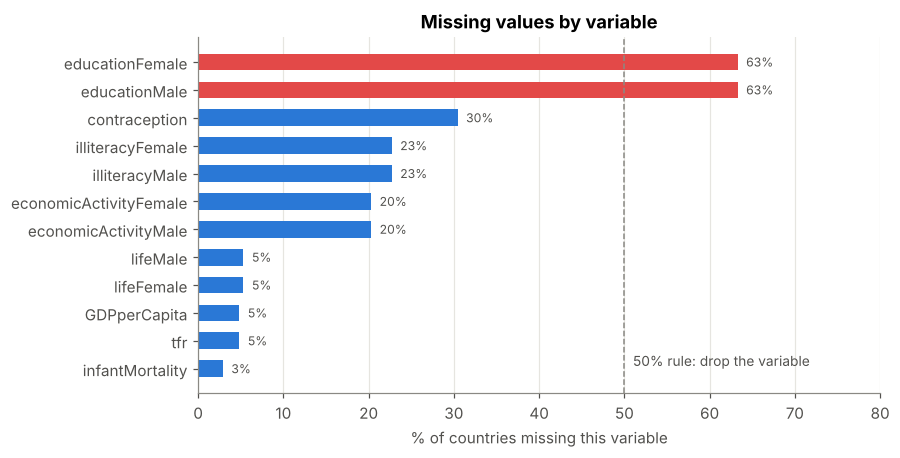

Dropped (> 50% missing): ['educationMale', 'educationFemale']
Kept (10): ['tfr', 'contraception', 'lifeMale', 'lifeFemale', 'infantMortality', 'GDPperCapita', 'economicActivityMale', 'economicActivityFemale', 'illiteracyMale', 'illiteracyFemale']


In [5]:
miss_pct = (raw[NUMERIC].isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(miss_pct.index, miss_pct.values, color=[RED if v > 50 else BLUE for v in miss_pct.values], height=0.6)
ax.axvline(50, color=MUTED, ls="--", lw=1)
ax.text(51, 0.1, "50% rule: drop the variable", color=INK2, fontsize=9)
for i, v in enumerate(miss_pct.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8, color=INK2)
ax.set_xlim(0, 80); ax.set_xlabel("% of countries missing this variable")
ax.set_title("Missing values by variable"); ax.grid(axis="y", visible=False)
plt.savefig(FIG / "01_missing_by_variable.png"); plt.show()

DROP_VARS = miss_pct[miss_pct > 50].index.tolist()
FEATURES_RAW = [c for c in NUMERIC if c not in DROP_VARS]
print("Dropped (> 50% missing):", DROP_VARS)
print(f"Kept ({len(FEATURES_RAW)}):", FEATURES_RAW)

**Decision 1 — drop `educationMale` and `educationFemale`** (63% missing, 131 of 207 countries). All three of our drafts reached this conclusion independently. Imputing two-thirds of a column would mean inventing most of it, and schooling is largely captured by the two illiteracy variables, which are far more complete. **10 variables remain.**

### 1.3 Which countries stay? (missing values by country)

In [6]:
row_missing = raw[FEATURES_RAW].isna().sum(axis=1)
print("Missing variables per country (out of 10):")
print(row_missing.value_counts().sort_index().rename("countries").to_frame().T.to_string())

MAX_MISSING = 4
dropped = raw.loc[row_missing > MAX_MISSING, ["country", "region"]].assign(n_missing=row_missing[row_missing > MAX_MISSING])
print(f"\nDropped ({len(dropped)} countries with more than {MAX_MISSING} of 10 variables missing):")
print(dropped.to_string(index=False))

Missing variables per country (out of 10):
           0   1   2   3   4   5   6   9   10
countries  97  30  41  15   8   7   6   1   2

Dropped (16 countries with more than 4 of 10 variables missing):
       country  region  n_missing
       Albania  Europe          5
       Andorra  Europe         10
        Angola  Africa          5
       Antigua America          5
        Bosnia  Europe          5
      Dominica America          6
    East.Timor    Asia          6
    Gaza.Strip    Asia          6
       Grenada America          5
 Liechtenstein  Europe          6
        Monaco  Europe          9
    San.Marino  Europe          5
       Somalia  Africa          5
        Tuvalu Oceania         10
Virgin.Islands America          6
Western.Sahara  Africa          6


**Decision 2 — drop countries missing more than 4 of the 10 variables (16 countries).** For these, at least half of the profile would be imputed, so their cluster would mostly reflect our assumptions rather than their data. They are mainly micro-states (Andorra, Monaco, San Marino, Liechtenstein, Tuvalu…) and places where data collection was disrupted (Somalia, Bosnia, Gaza Strip, Western Sahara).

*Why this matters:* one draft kept all 207 countries and filled every gap with the global median. That put Monaco, San Marino and Liechtenstein — which have almost no data — into the rich cluster, and Andorra into a middle one, purely on the basis of imputed values. **191 countries remain.**

In [7]:
df = raw.loc[row_missing <= MAX_MISSING, ["country", "region"] + FEATURES_RAW].reset_index(drop=True)
miss_mask = df[FEATURES_RAW].isna()
print(f"Countries kept: {len(df)}  |  cells still missing: {int(miss_mask.values.sum())} of {miss_mask.size} ({miss_mask.values.mean():.1%})")

Countries kept: 191  |  cells still missing: 189 of 1910 (9.9%)


### 1.4 Are the values missing at random? (this decides how to fill them)
For each variable with gaps, we compare the GDP per capita of countries where it is **missing** with countries where it is **observed**, using a **Mann-Whitney U test** (two independent groups, GDP very skewed → non-parametric test). H0: missingness is unrelated to wealth. A low p-value rejects H0.

In [8]:
rows = []
for col in FEATURES_RAW:
    m = df[col].isna()
    if m.sum() == 0 or col == "GDPperCapita":
        continue
    a, b = df.loc[m, "GDPperCapita"].dropna(), df.loc[~m, "GDPperCapita"].dropna()
    p = stats.mannwhitneyu(a, b).pvalue if len(a) > 0 else np.nan
    rows.append({"variable": col, "n missing": int(m.sum()),
                 "median GDP where missing": a.median(), "median GDP where observed": b.median(),
                 "Mann-Whitney p": round(p, 4), "related to wealth?": "YES" if p < 0.05 else "no"})
mcar = pd.DataFrame(rows).set_index("variable")
mcar

,n missing,median GDP where missing,median GDP where observed,Mann-Whitney p,related to wealth?
variable,,,,,
tfr,3,11789.5,1764.0,0.8593,no
contraception,50,4510.5,1565.0,0.0288,YES
lifeMale,4,2305.0,1712.0,0.9614,no
lifeFemale,4,2305.0,1712.0,0.9614,no
economicActivityMale,31,382.0,2352.0,0.0000,YES
economicActivityFemale,31,382.0,2352.0,0.0000,YES
illiteracyMale,31,18943.0,1513.0,0.0000,YES
illiteracyFemale,31,18943.0,1513.0,0.0000,YES


**The gaps are not random — they follow development.**
* `illiteracy` is missing mostly for **rich** countries (median GDP of countries with a gap ≈ \$18,900 vs \$1,500 where it is reported; p < 0.001). Rich countries simply stopped reporting it.
* `economicActivity` is missing mostly for **poor** countries (≈ \$380 vs \$2,350; p < 0.001).
* `contraception` is also more often missing in richer countries (p = 0.03). The other variables have only 3–4 gaps each.

**Consequence — Decision 3:** filling gaps with a single global median (the approach in Session 7 and in one of our drafts) is **biased**: every rich country with no illiteracy figure would receive the illiteracy of a typical, much poorer country. We instead predict each missing value from the country's other indicators (Step 1.6).

### 1.5 Detect outliers and decide how to treat them

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out = pd.DataFrame({"skewness": df[FEATURES_RAW].skew().round(2),
                    "IQR outliers": df[FEATURES_RAW].apply(iqr_outliers)})
out

,skewness,IQR outliers
tfr,0.50,0
contraception,-0.07,0
lifeMale,-0.81,1
lifeFemale,-0.84,0
infantMortality,1.10,4
GDPperCapita,1.97,25
economicActivityMale,-0.34,1
economicActivityFemale,-0.09,3
illiteracyMale,1.11,2
illiteracyFemale,0.78,0


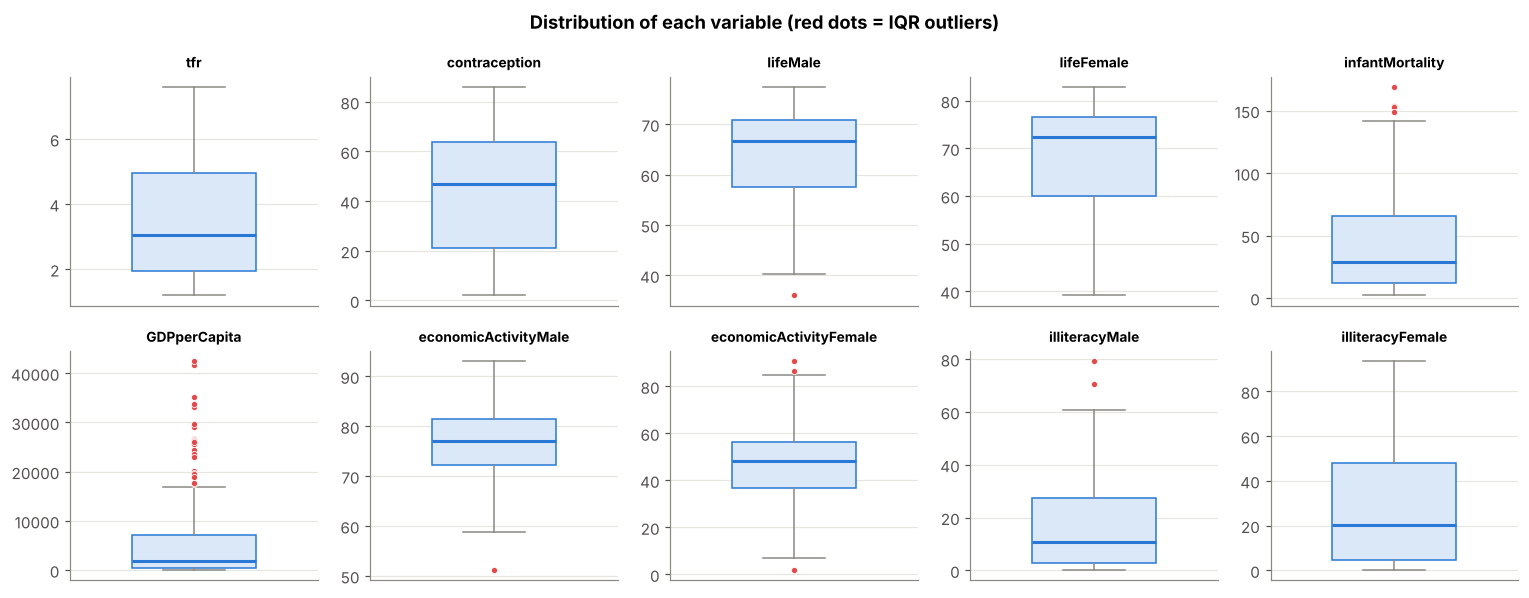

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5.5))
for ax, col in zip(axes.ravel(), FEATURES_RAW):
    ax.boxplot(df[col].dropna(), widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#dbe8f8", edgecolor=BLUE),
               medianprops=dict(color=BLUE, lw=2), whiskerprops=dict(color=MUTED),
               capprops=dict(color=MUTED), flierprops=dict(marker="o", ms=4, mfc=RED, mec="white", mew=0.5))
    ax.set_title(col, fontsize=9); ax.set_xticks([])
fig.suptitle("Distribution of each variable (red dots = IQR outliers)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "02_boxplots.png"); plt.show()

In [11]:
print("Richest countries by GDP per capita:")
print(df.nlargest(6, "GDPperCapita")[["country", "GDPperCapita"]].to_string(index=False))
print("\nLowest reported illiteracy (male %, female %):")
print(df.nsmallest(8, "illiteracyMale")[["country", "illiteracyMale", "illiteracyFemale"]].to_string(index=False))

Richest countries by GDP per capita:
    country  GDPperCapita
Switzerland       42416.0
      Japan       41718.0
 Luxembourg       35109.0
     Norway       33734.0
    Denmark       33191.0
    Germany       29632.0

Lowest reported illiteracy (male %, female %):
       country  illiteracyMale  illiteracyFemale
       Estonia           0.200             0.200
        Latvia           0.200             0.300
  Turkmenistan           0.200             0.400
    Uzbekistan           0.200             0.400
American.Samoa           0.264             0.360
      Slovenia           0.264             0.432
         Tonga           0.264             0.504
       Armenia           0.300             0.500


**What the checks show**
* `GDPperCapita` is by far the most skewed variable (skewness ≈ 2) with 25 IQR outliers — all of them genuinely rich countries (Switzerland, Japan, Luxembourg, Norway…). On a raw scale, going from \$20,000 to \$40,000 would count as much as going from \$300 to \$20,300; economically that is wrong, because income gains matter *proportionally*.
* The few other outliers (infant mortality, illiteracy, economic activity) are real observations — e.g. very high infant mortality in Sierra Leone or very low female labour participation in the Gulf. They are exactly the differences we want the clusters to capture.
* Illiteracy below 1% is reported for many former Soviet countries (Estonia, Latvia, Uzbekistan: 0.2%). These are plausible but probably reflect different measurement definitions.

**Decision 4 — log-transform GDP per capita only; keep all other values (no deletion, no capping).**
One of our drafts also log-transformed infant mortality and illiteracy. We tested this carefully (Part 3.6): logging **illiteracy** stretches the gap between 0.3% and 3% to the same size as the gap between 3% and 30%. Combined with the suspiciously low ex-Soviet values, it creates a separate "near-zero illiteracy" cluster that is driven by tiny, possibly definitional differences. Infant mortality and illiteracy are bounded rates with only moderate skew (~1), so we keep them on their original scale. Because K-Means is sensitive to extreme points, Part 3.6 also checks that removing the multivariate outliers barely changes the clusters.

In [12]:
df["logGDP"] = np.log10(df["GDPperCapita"])
FEATURES = ["tfr", "contraception", "lifeMale", "lifeFemale", "infantMortality",
            "logGDP", "economicActivityMale", "economicActivityFemale",
            "illiteracyMale", "illiteracyFemale"]
print(f"Skewness of GDP per capita: raw {df.GDPperCapita.skew():.2f}  ->  log10 {df.logGDP.skew():.2f}")

Skewness of GDP per capita: raw 1.97  ->  log10 0.02


### 1.6 Fill the remaining gaps (imputation)
We use `IterativeImputer`: each missing value is predicted by a regression on all the other variables, repeated until the values settle (the same family as MICE/EM). Because Step 1.4 showed that missingness follows development, and the other nine indicators measure development well, they give plausible values where a single median cannot.

In [13]:
imputer = IterativeImputer(max_iter=50, random_state=0)
X_imp = pd.DataFrame(imputer.fit_transform(df[FEATURES]), columns=FEATURES)

# Region-median imputation is kept for the robustness check in Part 3
X_reg = df[FEATURES].copy()
for col in FEATURES:
    X_reg[col] = X_reg[col].fillna(df.groupby("region")[col].transform("median")).fillna(df[col].median())
# Global-median imputation (the Session 7 approach), also for comparison
X_glob = df[FEATURES].fillna(df[FEATURES].median())

feat_mask = df[FEATURES].isna()
cmp = pd.DataFrame({
    "n imputed": feat_mask.sum(),
    "mean of observed values": df[FEATURES].mean(),
    "mean of imputed (regression)": X_imp[feat_mask].mean(),
    "mean of imputed (global median)": X_glob[feat_mask].mean(),
}).loc[lambda t: t["n imputed"] > 0].round(2)
cmp

,n imputed,mean of observed values,mean of imputed (regression),mean of imputed (global median)
tfr,3,3.49,3.10,3.06
contraception,50,43.24,47.83,47.00
lifeMale,4,63.79,67.06,66.60
lifeFemale,4,68.57,71.25,72.30
logGDP,4,3.28,3.69,3.25
economicActivityMale,31,76.56,79.18,77.05
economicActivityFemale,31,46.56,46.06,48.10
illiteracyMale,31,17.55,6.23,10.83
illiteracyFemale,31,27.91,8.80,20.10


**Why regression imputation matters here:** for the 31 countries with no illiteracy figure (mostly rich), regression imputation gives on average **6.2% male / 8.8% female illiteracy** — consistent with their other indicators. The global median would have given them **10.8% / 20.1%**, i.e. a rich country would be assigned one in five women illiterate. Only **9.9% of all cells** (189 of 1,910) are imputed. An imputed value is still an estimate, so in Part 4 we only use well-measured countries as representatives, and in Part 3.6 we check that region-median and global-median imputation give similar clusters.

### 1.7 Scale the variables — and why scaling matters
PCA finds directions of maximum **variance** and K-Means uses **Euclidean distance**, so both depend on the units of measurement. A variable measured in large units would dominate purely because of its units.

In [14]:
print("Variance of each variable before scaling (raw GDP shown for comparison):")
print(pd.concat([df[["GDPperCapita"]], X_imp]).var().apply(lambda v: f"{v:,.1f}").to_string())

pca_raw_gdp = PCA().fit(df[FEATURES_RAW].fillna(df[FEATURES_RAW].median()))
pca_unscaled = PCA().fit(X_imp)
top = pd.Series(np.abs(pca_unscaled.components_[0]), index=FEATURES).idxmax()
print(f"\nPCA on raw (unlogged, unscaled) data: PC1 explains {pca_raw_gdp.explained_variance_ratio_[0]:.1%} and is essentially GDP per capita.")
print(f"PCA on log-GDP data without scaling : PC1 explains {pca_unscaled.explained_variance_ratio_[0]:.1%} and is dominated by '{top}'.")

scaler = StandardScaler()
X = scaler.fit_transform(X_imp)
pca_scaled_check = PCA().fit(X)
print(f"PCA after standardising             : PC1 explains {pca_scaled_check.explained_variance_ratio_[0]:.1%} and mixes many variables.")

Variance of each variable before scaling (raw GDP shown for comparison):
GDPperCapita              81,195,017.8
tfr                                2.9
contraception                    549.9
lifeMale                          93.2
lifeFemale                       118.6
infantMortality                1,457.9
logGDP                             0.5
economicActivityMale              54.0
economicActivityFemale           256.0
illiteracyMale                   300.3
illiteracyFemale                 682.7

PCA on raw (unlogged, unscaled) data: PC1 explains 100.0% and is essentially GDP per capita.
PCA on log-GDP data without scaling : PC1 explains 80.0% and is dominated by 'infantMortality'.
PCA after standardising             : PC1 explains 67.1% and mixes many variables.


**Decision 5 — standardise every variable to mean 0 and standard deviation 1 (`StandardScaler`).** Without scaling, PCA simply rediscovers whichever variable has the largest numbers (GDP in dollars, or contraception in percentage points after logging GDP) — a units artefact, not a pattern. After standardising, every indicator has an equal chance to shape the components and the distances, so the *correlations* between them decide the result.

### 1.8 Multivariate outliers (Mahalanobis distance)
A country can have no extreme value on any single variable but an unusual *combination*. Mahalanobis D² measures distance from the centre of the cloud taking correlations into account; we flag countries with p < 0.001 against a χ²(10) distribution.

In [15]:
D2 = np.einsum("ij,jk,ik->i", X, np.linalg.inv(np.cov(X.T)), X)
pval = stats.chi2.sf(D2, df=X.shape[1])
is_outlier = pval < 0.001
out_tbl = df.loc[is_outlier, ["country", "region"]].assign(D2=D2[is_outlier].round(1),
                                                           n_imputed=feat_mask[is_outlier].sum(axis=1).values)
print(f"Multivariate outliers (p < 0.001): {is_outlier.sum()}")
out_tbl

Multivariate outliers (p < 0.001): 1


,country,region,D2,n_imputed
105,Maldives,Asia,33.0,1


Only **Maldives** is a multivariate outlier: its female life expectancy (63) is *below* the male one (66) while fertility is very high (6.8) — an unusual combination, but a real one. **Decision: keep it.** Removing real countries would remove the diversity we want to study, and Part 3.6 shows the clusters are essentially unchanged without it (ARI 0.98).

### Summary of preparation decisions

| # | Decision | Why |
|---|---|---|
| 1 | Drop `educationMale`, `educationFemale` | 63% missing; the information overlaps with illiteracy |
| 2 | Drop 16 countries missing more than 4 of 10 variables | Their profile would be mostly imputed |
| 3 | Fill remaining gaps with regression imputation (`IterativeImputer`) | Missingness depends on development (Mann-Whitney), so a single median is biased |
| 4 | `log10(GDPperCapita)` only; keep all outliers | GDP is extremely skewed and proportional; other extreme values are real signal, and logging near-zero illiteracy would exaggerate tiny differences |
| 5 | Standardise all variables (z-scores) | PCA and K-Means depend on units; otherwise one variable dominates |

**Final matrix: 191 countries × 10 variables.**

---
## Part 2 — PCA: Understand the Structure of the Data

### 2.1 Are the data suitable for PCA?
* **Bartlett's test of sphericity** — H0: the variables are uncorrelated (correlation matrix = identity). We *want* to reject it: PCA needs correlated variables to compress.
* **KMO (Kaiser-Meyer-Olkin)** — share of correlation that is genuinely shared; above 0.8 is "meritorious".

Bartlett's test: chi2 = 2,647.9, df = 45, p = 0
KMO = 0.86


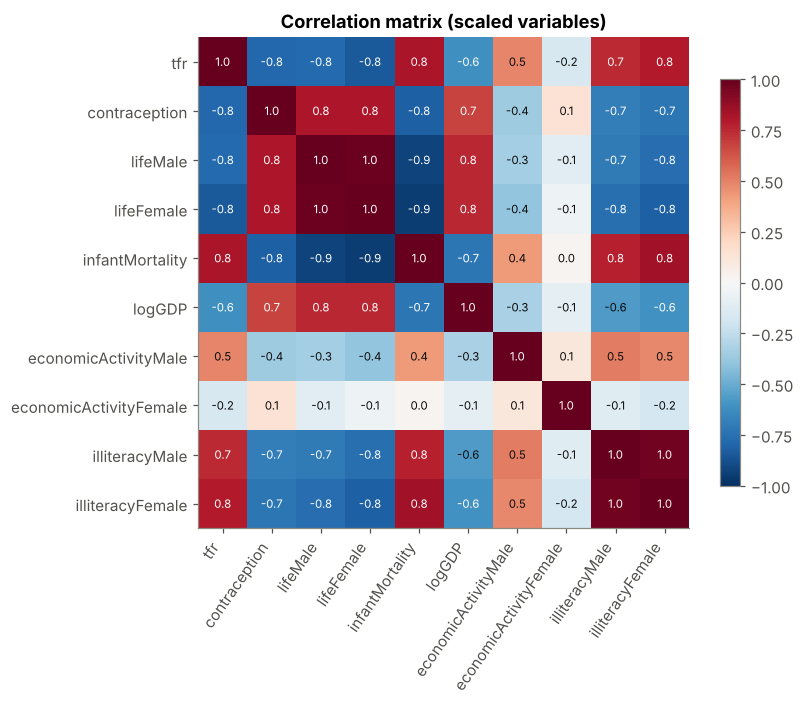

In [16]:
n, p = X.shape
R = np.corrcoef(X.T)
chi2_stat = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
dof = p * (p - 1) / 2
print(f"Bartlett's test: chi2 = {chi2_stat:,.1f}, df = {dof:.0f}, p = {stats.chi2.sf(chi2_stat, dof):.3g}")
Rinv = np.linalg.inv(R)
partial = -Rinv / np.sqrt(np.outer(np.diag(Rinv), np.diag(Rinv)))
np.fill_diagonal(partial, 0)
R0 = R.copy(); np.fill_diagonal(R0, 0)
kmo = (R0 ** 2).sum() / ((R0 ** 2).sum() + (partial ** 2).sum())
print(f"KMO = {kmo:.2f}")

fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(p)); ax.set_xticklabels(FEATURES, rotation=55, ha="right")
ax.set_yticks(range(p)); ax.set_yticklabels(FEATURES)
for i in range(p):
    for j in range(p):
        ax.text(j, i, f"{R[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(R[i, j]) > 0.6 else INK)
ax.grid(False); ax.set_title("Correlation matrix (scaled variables)")
plt.colorbar(im, shrink=0.8)
plt.savefig(FIG / "03_correlation.png"); plt.show()

**The data are well suited to PCA.** Bartlett's test strongly rejects "no correlation" (χ² ≈ 2,648, df = 45, p ≈ 0) and **KMO = 0.86** ("meritorious"). The heat-map shows why: life expectancy, infant mortality, fertility, contraception, illiteracy and income are strongly inter-correlated. In a regression this multicollinearity would be a problem; here it is exactly the redundancy PCA compresses. The two economic-activity variables are only weakly linked to the rest, which matters for PC2 and PC3.

### 2.2 How much variance does each component explain? How many for 90%+?

In [17]:
pca = PCA(random_state=SEED).fit(X)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
eig = pca.explained_variance_
N90 = int(np.argmax(cum >= 0.90) + 1)
KAISER = int((eig > 1).sum())
pca_table = pd.DataFrame({"eigenvalue": eig.round(2), "% variance": (evr * 100).round(1),
                          "cumulative %": (cum * 100).round(1)},
                         index=[f"PC{i+1}" for i in range(len(evr))])
print(f"Components needed for >= 90% of the variance: {N90}  ({cum[N90-1]:.1%})")
print(f"Components with eigenvalue > 1 (Kaiser rule): {KAISER}")
pca_table

Components needed for >= 90% of the variance: 4  (91.8%)
Components with eigenvalue > 1 (Kaiser rule): 2


,eigenvalue,% variance,cumulative %
PC1,6.75,67.1,67.1
PC2,1.17,11.6,78.7
PC3,0.87,8.7,87.4
PC4,0.44,4.4,91.8
PC5,0.34,3.4,95.2
PC6,0.21,2.1,97.3
PC7,0.17,1.7,98.9
PC8,0.07,0.7,99.6
PC9,0.03,0.3,99.9
PC10,0.01,0.1,100.0


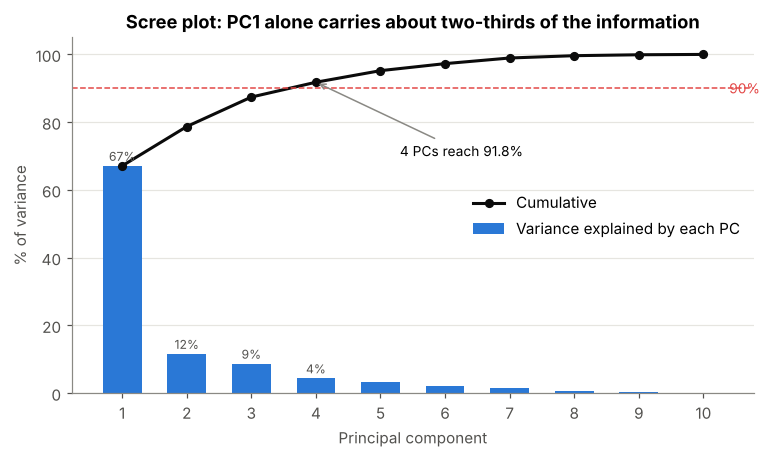

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.2))
pcs = np.arange(1, len(evr) + 1)
ax.bar(pcs, evr * 100, color=BLUE, width=0.6, label="Variance explained by each PC")
ax.plot(pcs, cum * 100, color=INK, lw=2, marker="o", ms=5, label="Cumulative")
ax.axhline(90, color=RED, ls="--", lw=1)
ax.text(10.4, 90, "90%", color=RED, va="center", fontsize=9)
ax.annotate(f"{N90} PCs reach {cum[N90-1]:.1%}", (N90, cum[N90-1] * 100), (N90 + 1.3, 70),
            arrowprops=dict(arrowstyle="->", color=MUTED), fontsize=9)
for x_, v in zip(pcs[:4], evr[:4]):
    ax.text(x_, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(pcs); ax.set_xlabel("Principal component"); ax.set_ylabel("% of variance")
ax.set_ylim(0, 105); ax.set_title("Scree plot: PC1 alone carries about two-thirds of the information")
ax.legend(loc="center right"); ax.grid(axis="x", visible=False)
plt.savefig(FIG / "04_scree.png"); plt.show()

| Component | Variance explained | Cumulative |
|---|---|---|
| PC1 | 67.1% | 67.1% |
| PC2 | 11.6% | 78.7% |
| PC3 | 8.7% | 87.4% |
| PC4 | 4.4% | **91.8%** |

* **Four components are needed to explain 90%+ of the variance (91.8%).**
* The Kaiser rule (eigenvalue > 1) would keep only 2 components; we use the 90% rule because we want to keep nearly all the information before clustering.
* **One single dimension (PC1) holds two-thirds of everything these ten indicators say about countries.**

### 2.3 Which variables contribute most to the main components?
The **loading** is the weight of a variable in a component; its square (in %) is the variable's **contribution**.

In [19]:
loadings = pd.DataFrame(pca.components_[:4].T, index=FEATURES, columns=["PC1", "PC2", "PC3", "PC4"])
FLIP = np.ones(4)
if loadings.loc["lifeFemale", "PC1"] < 0:          # orient PC1: positive = more developed
    FLIP[0] = -1
if loadings.loc["economicActivityFemale", "PC2"] < 0:  # orient PC2: positive = more women working
    FLIP[1] = -1
loadings = loadings * FLIP
contrib = (loadings ** 2 * 100).round(1)
print("Loadings:")
print(loadings.round(2).to_string())
print("\nContribution (%) to PC1 and PC2:")
print(contrib[["PC1", "PC2"]].sort_values("PC1", ascending=False).to_string())

Loadings:
                         PC1   PC2   PC3   PC4
tfr                    -0.35 -0.14  0.06 -0.14
contraception           0.34  0.10  0.18  0.28
lifeMale                0.36 -0.17  0.25 -0.04
lifeFemale              0.37 -0.10  0.17 -0.04
infantMortality        -0.37  0.07 -0.11  0.10
logGDP                  0.30 -0.19  0.24  0.50
economicActivityMale   -0.20  0.14  0.85 -0.39
economicActivityFemale  0.01  0.90  0.05  0.26
illiteracyMale         -0.34 -0.15  0.24  0.49
illiteracyFemale       -0.35 -0.18  0.16  0.42

Contribution (%) to PC1 and PC2:
                         PC1   PC2
lifeFemale              13.6   1.1
infantMortality         13.5   0.5
lifeMale                12.8   2.8
illiteracyFemale        12.3   3.3
tfr                     11.9   1.9
contraception           11.4   1.0
illiteracyMale          11.3   2.3
logGDP                   9.1   3.6
economicActivityMale     4.1   2.0
economicActivityFemale   0.0  81.5


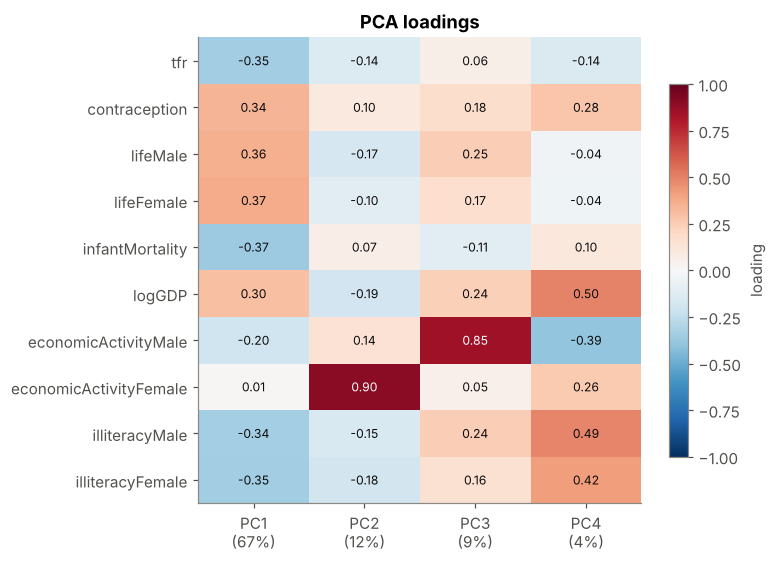

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
L = loadings.values
im = ax.imshow(L, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels([f"PC{i+1}\n({evr[i]:.0%})" for i in range(4)])
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        ax.text(j, i, f"{L[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(L[i, j]) > 0.55 else INK)
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8, label="loading")
ax.set_title("PCA loadings")
plt.savefig(FIG / "05_loadings.png"); plt.show()

**PC1 (67%) — overall development.** Nine of ten variables load almost equally: female and male life expectancy, contraception and log GDP on the positive side; infant mortality, fertility and illiteracy on the negative side. The largest contributions come from **female life expectancy (13.6%), infant mortality (13.5%), male life expectancy (12.8%) and female illiteracy (12.3%)**; **log GDP contributes less (9.1%)**. Development is a *bundle* — health, family size, education and income move together — and income is not the strongest single separator.

**PC2 (12%) — women in the labour force.** Female economic activity alone contributes **81.5%** of PC2. It is almost unrelated to PC1, so *how developed a country is* and *how many women work outside the home* are different things: many poor farming economies have high female activity, while several wealthy Gulf states have very low female activity.

**PC3 (9%)** is mostly male economic activity (labour-market structure: age structure, years of schooling, retirement). **PC4 (4%)** mixes income, literacy and contraception and is hard to interpret.

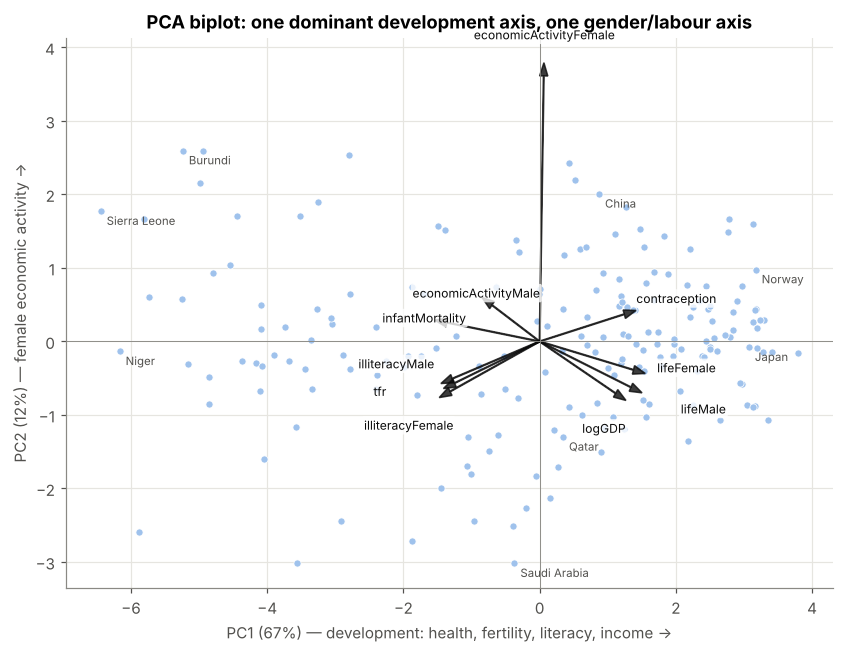

In [21]:
scores = pca.transform(X)
scores[:, :4] *= FLIP
for i in range(4):
    df[f"PC{i+1}"] = scores[:, i]
Z = scores[:, :N90]          # the space we cluster in

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(df.PC1, df.PC2, s=22, color="#9fc2ec", edgecolor="white", lw=0.5)
scale = 4.2
nudge = {"illiteracyMale": (-0.55, 0.4), "illiteracyFemale": (-0.3, -0.3), "tfr": (-0.75, -0.05),
         "lifeMale": (0.75, -0.15), "lifeFemale": (0.45, 0.12), "logGDP": (-0.45, -0.3), "contraception": (0.45, 0.12)}
for f in FEATURES:
    x_, y_ = loadings.loc[f, "PC1"] * scale, loadings.loc[f, "PC2"] * scale
    ax.arrow(0, 0, x_, y_, color=INK, width=0.01, head_width=0.12, length_includes_head=True, alpha=0.8)
    dx, dy = nudge.get(f, (0, 0))
    ax.text(x_ * 1.1 + dx, y_ * 1.1 + dy, f, fontsize=8, ha="center", va="center", color=INK,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
for c in ["Norway", "Japan", "Niger", "Sierra.Leone", "Saudi.Arabia", "China", "Burundi", "Qatar"]:
    r = df[df.country == c].iloc[0]
    ax.annotate(c.replace(".", " "), (r.PC1, r.PC2), fontsize=7.5, color=INK2, xytext=(4, -9), textcoords="offset points")
ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
ax.set_xlabel(f"PC1 ({evr[0]:.0%}) — development: health, fertility, literacy, income →")
ax.set_ylabel(f"PC2 ({evr[1]:.0%}) — female economic activity →")
ax.set_title("PCA biplot: one dominant development axis, one gender/labour axis")
plt.savefig(FIG / "06_biplot.png"); plt.show()

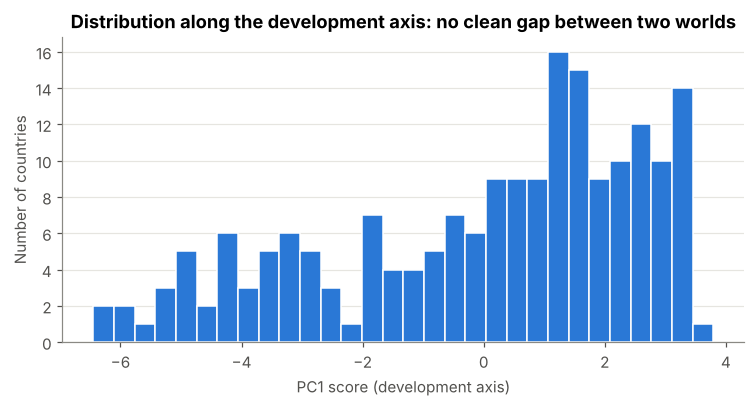

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df.PC1, bins=30, color=BLUE, edgecolor="white")
ax.set_xlabel("PC1 score (development axis)"); ax.set_ylabel("Number of countries")
ax.set_title("Distribution along the development axis: no clean gap between two worlds")
ax.grid(axis="x", visible=False)
plt.savefig(FIG / "07_pc1_hist.png"); plt.show()

The **shape** of the cloud matters: countries form a **continuous band** along PC1 rather than two separated blobs. The histogram has a denser group on the right (rich and healthy) and a long tail on the left, but no empty gap that would separate a "developed" from a "developing" world — Rosling's point that most countries sit in the middle. Along PC2, Saudi Arabia (very few women in the labour force) and China (many) sit far apart even though both are in the middle of PC1.

### 2.4 Is PCA useful for reducing the dimensionality before clustering?
We cluster into 4 groups using the first *m* PCs and compare with clustering on all 10 scaled variables (Adjusted Rand Index: 1 = identical groups, 0 = chance agreement).

In [23]:
base = KMeans(4, n_init=50, random_state=SEED).fit(X)
rows = []
for m in [2, 3, 4, 5, 10]:
    lab = KMeans(4, n_init=50, random_state=SEED).fit_predict(scores[:, :m])
    rows.append({"PCs used": m, "variance kept %": round(cum[m-1] * 100, 1),
                 "ARI vs all 10 variables": round(adjusted_rand_score(base.labels_, lab), 2)})
pd.DataFrame(rows).set_index("PCs used")

,variance kept %,ARI vs all 10 variables
PCs used,,
2,78.7,0.89
3,87.4,0.75
4,91.8,0.90
5,95.2,0.90
10,100.0,1.00


**Yes, PCA is useful before clustering.**
* It compresses 10 correlated variables into **4 uncorrelated components that keep 91.8% of the variance**; the 6 dropped components carry only 8% and are mostly noise.
* It removes double-counting: near-duplicates (male/female life expectancy, male/female illiteracy, infant mortality vs life expectancy) would otherwise count "health" and "literacy" twice in the K-Means distance.
* Clustering on 4 PCs gives almost the same 4 groups as clustering on all 10 variables (**ARI 0.90**), so little is lost.
* The first 2 PCs (79%) give a faithful map to **visualise** the clusters.

**We therefore cluster on the first 4 principal-component scores.**

---
## Part 3 — PCA + Clustering: How Many Worlds?

### 3.1 Start with k = 2: "developed" vs "developing"

In [24]:
def order_labels(labels):
    # Relabel clusters 1..k from least to most developed (mean PC1)
    means = pd.Series(df.PC1.values).groupby(np.asarray(labels)).mean().sort_values()
    mapping = {old: new for new, old in enumerate(means.index, start=1)}
    return np.array([mapping[l] for l in labels])

def fit_km(k, data=None, n_init=300):
    data = Z if data is None else data
    km = KMeans(n_clusters=k, n_init=n_init, random_state=SEED).fit(data)
    return km, order_labels(km.labels_)

km2, df["k2"] = fit_km(2)
total_ss = ((Z - Z.mean(0)) ** 2).sum()
print("Cluster sizes:", df.k2.value_counts().sort_index().to_dict())
print(f"Silhouette (k=2): {silhouette_score(Z, df.k2):.3f}   |   R² (between-cluster share): {1 - km2.inertia_ / total_ss:.1%}")

profile_cols = ["tfr", "contraception", "lifeFemale", "infantMortality", "GDPperCapita",
                "economicActivityFemale", "illiteracyFemale"]
k2_profile = df.groupby("k2")[profile_cols].median().round(1)
k2_profile.insert(0, "n", df.k2.value_counts().sort_index())
k2_profile.index = ["C1 'developing'", "C2 'developed'"]
k2_profile

Cluster sizes: {1: 59, 2: 132}
Silhouette (k=2): 0.494   |   R² (between-cluster share): 55.9%


,n,tfr,contraception,lifeFemale,infantMortality,GDPperCapita,economicActivityFemale,illiteracyFemale
C1 'developing',59,5.4,18.0,54.2,86.0,382.0,44.9,58.2
C2 'developed',132,2.3,59.0,75.3,17.0,3381.0,48.4,9.0


In [25]:
big = df[df.k2 == 2]
print(f"Inside the 'developed' cluster (n={len(big)}):")
for col in ["GDPperCapita", "infantMortality", "tfr", "lifeFemale", "illiteracyFemale"]:
    lo, hi = big.loc[big[col].idxmin()], big.loc[big[col].idxmax()]
    print(f"  {col:17s} from {lo[col]:>8.1f} ({lo.country}) to {hi[col]:>8.1f} ({hi.country})")
print("\nRegion composition:")
print(pd.crosstab(df.k2.map({1: "C1 'developing'", 2: "C2 'developed'"}), df.region).to_string())
for c in (1, 2):
    print(f"\nC{c}: " + textwrap.fill(", ".join(df[df.k2 == c].country.str.replace(".", " ", regex=False)), 120))

Inside the 'developed' cluster (n=132):
  GDPperCapita      from    122.0 (Tajikistan) to  42416.0 (Switzerland)
  infantMortality   from      2.0 (Northern.Mariana.Islands) to     78.0 (Myanmar)
  tfr               from      1.2 (Italy) to      7.2 (Oman)
  lifeFemale        from     61.8 (Myanmar) to     82.9 (France)
  illiteracyFemale  from      0.2 (Estonia) to     51.0 (Algeria)

Region composition:
region           Africa  America  Asia  Europe  Oceania
k2                                                     
C1 'developing'      44        2    11       0        2
C2 'developed'        8       35    37      38       14

C1: Afghanistan, Bangladesh, Benin, Bhutan, Botswana, Burkina Faso, Burundi, Cambodia, Cameroon, Central African Rep, Chad,
Comoros, Congo, Dem Rep of the Congo, Djibouti, Egypt, Equatorial Guinea, Eritrea, Ethiopia, Gabon, Gambia, Ghana,
Guatemala, Guinea, Guinea Bissau, Haiti, India, Iraq, Ivory Coast, Kenya, Kiribati, Laos, Lesotho, Liberia, Madagascar,
Malawi,

**What k = 2 actually finds.** The split is **59 vs 132**, and it is statistically clear (silhouette 0.49). Cluster 1 is the high-fertility, high-mortality group: mostly sub-Saharan Africa plus Afghanistan, Pakistan, India, Bangladesh, Nepal, Haiti, Yemen, Egypt and Morocco.

But the **"developed" cluster contains everyone else**: Switzerland and Norway together with Tajikistan, Bolivia, Myanmar and Oman. Inside it, GDP per capita ranges from **\$122 (Tajikistan) to \$42,416 (Switzerland)** — a 350× range — infant mortality from 2 to 78 per 1,000 and fertility from 1.2 to 7.2 children. The two clusters capture only **56% of the structure** (R²). Calling all 132 countries "developed" is not meaningful: the two-group split separates a *tail* from the rest and hides the large middle of the world.

### 3.2 Testing k = 2 … 10: Elbow Rule, silhouette and other evidence

| Evidence | What it measures | Better is |
|---|---|---|
| **Elbow rule** (inertia / within-cluster SS) | How much tighter clusters get with each extra cluster | where the curve bends |
| **Silhouette** | How well each country fits its own cluster vs. the next (−1 to 1) | higher |
| **Calinski-Harabasz** | Between- vs. within-cluster spread | higher |
| **Davies-Bouldin** | Average overlap between clusters | lower |
| **R²** (between-cluster SS / total SS) | Share of the data's structure captured by the clusters | higher (always grows with k) |
| **Bootstrap stability** | Re-cluster 100 resamples; mean ARI with the full-data solution | higher |

We use 300 random starts for K-Means: with few starts the 4-cluster solution can land on slightly different local optima.

In [26]:
K = list(range(2, 11))
rng = np.random.default_rng(SEED)
boot_idx = [rng.choice(len(Z), len(Z), replace=True) for _ in range(100)]
rows, FITS = [], {}
for k in K:
    km, lab = fit_km(k)
    FITS[k] = lab
    stab = [adjusted_rand_score(lab, KMeans(k, n_init=10, random_state=b).fit(Z[idx]).predict(Z))
            for b, idx in enumerate(boot_idx)]
    rows.append(dict(k=k, inertia=km.inertia_, R2=1 - km.inertia_ / total_ss,
                     silhouette=silhouette_score(Z, lab),
                     calinski_harabasz=calinski_harabasz_score(Z, lab),
                     davies_bouldin=davies_bouldin_score(Z, lab),
                     stability=np.mean(stab), stability_sd=np.std(stab),
                     smallest=np.bincount(lab)[1:].min()))
metrics = pd.DataFrame(rows).set_index("k")
metrics["inertia drop %"] = -metrics.inertia.pct_change() * 100

x_ = np.array(K, float); y_ = metrics.inertia.values
xn, yn = (x_ - x_.min()) / (x_.max() - x_.min()), (y_ - y_.min()) / (y_.max() - y_.min())
metrics["elbow_distance"] = np.abs(yn - (1 - xn)) / np.sqrt(2)   # distance to chord between first and last point
ELBOW_K = int(metrics.elbow_distance.idxmax())
print("Objective elbow (max distance to chord):", ELBOW_K)
metrics.round(3)

Objective elbow (max distance to chord): 5


,inertia,R2,silhouette,calinski_harabasz,davies_bouldin,stability,stability_sd,smallest,inertia drop %,elbow_distance
k,,,,,,,,,,
2,772.846,0.559,0.494,239.751,0.777,0.940,0.059,59,NaN,0.000
3,589.069,0.664,0.333,185.768,1.131,0.776,0.139,44,23.779,0.168
4,492.421,0.719,0.279,159.599,1.212,0.755,0.153,37,16.407,0.215
5,427.509,0.756,0.272,144.197,1.232,0.709,0.168,27,13.182,0.217
6,380.681,0.783,0.264,133.403,1.140,0.621,0.139,26,10.954,0.194
7,340.663,0.806,0.267,127.159,1.115,0.590,0.109,13,10.512,0.161
8,307.988,0.824,0.271,122.675,1.140,0.651,0.104,12,9.592,0.119
9,284.704,0.838,0.277,117.346,1.098,0.655,0.087,9,7.560,0.063
10,266.327,0.848,0.274,112.280,1.122,0.628,0.081,10,6.455,0.000


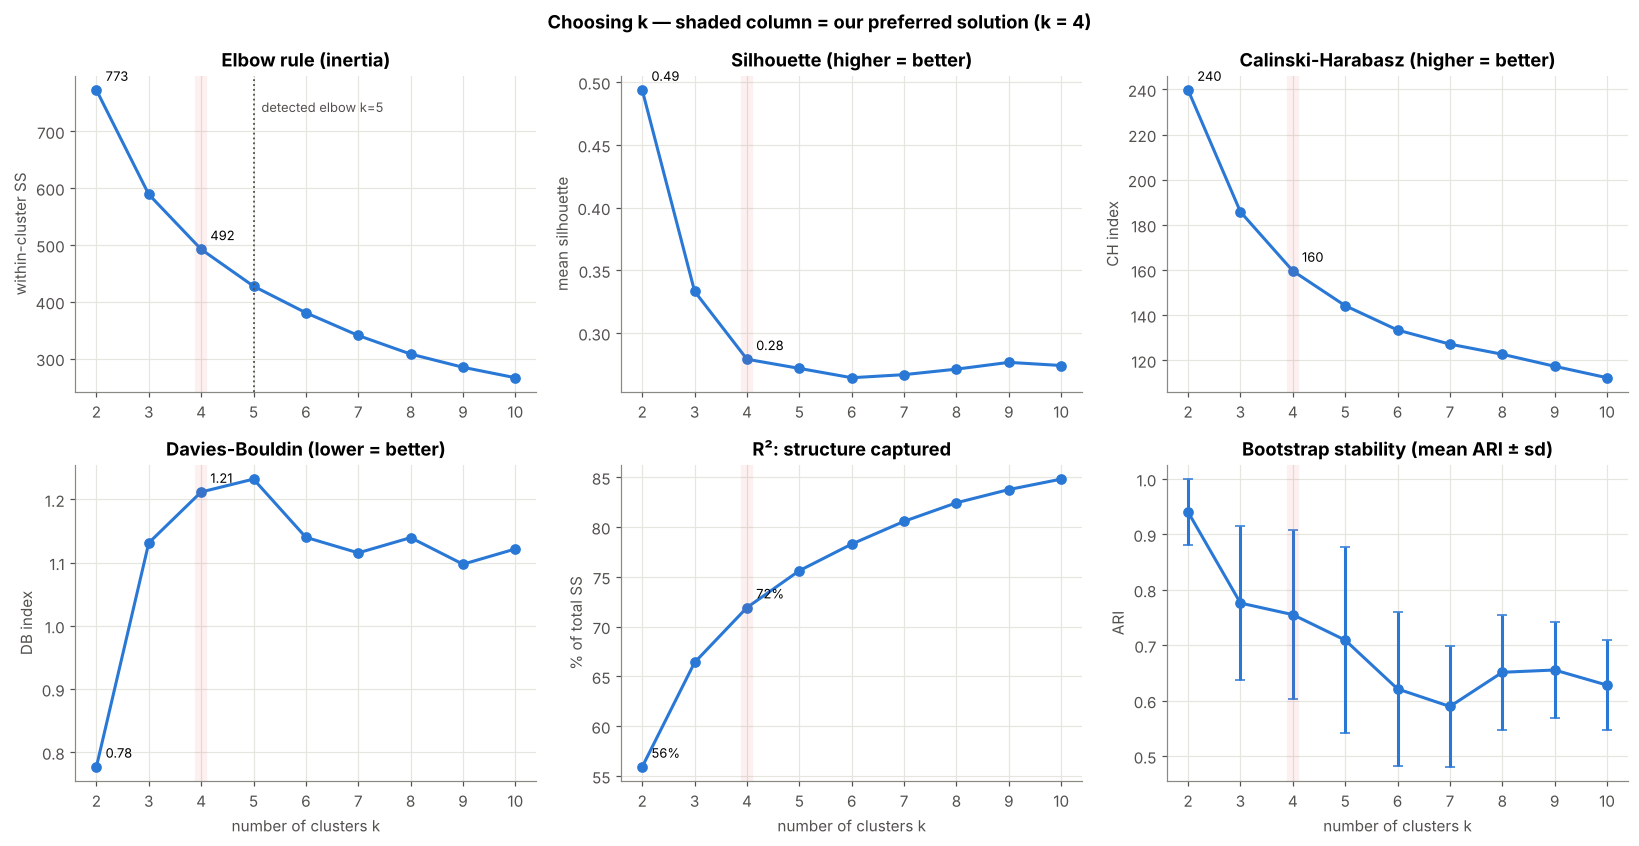

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.8))
def panel(ax, y, title, ylabel, fmt="{:.2f}", lab_ks=(2, 4)):
    ax.plot(K, y, color=BLUE, lw=2, marker="o", ms=6)
    for k in lab_ks:
        ax.annotate(fmt.format(y[K.index(k)]), (k, y[K.index(k)]), (6, 6), textcoords="offset points", fontsize=8.5)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xticks(K)
    ax.axvline(4, color=RED, lw=8, alpha=0.08)

panel(axes[0, 0], metrics.inertia.values, "Elbow rule (inertia)", "within-cluster SS", "{:.0f}")
axes[0, 0].axvline(ELBOW_K, color=INK2, ls=":", lw=1.2)
axes[0, 0].text(ELBOW_K + 0.15, metrics.inertia.max() * 0.95, f"detected elbow k={ELBOW_K}", fontsize=8.5, color=INK2)
panel(axes[0, 1], metrics.silhouette.values, "Silhouette (higher = better)", "mean silhouette")
panel(axes[0, 2], metrics.calinski_harabasz.values, "Calinski-Harabasz (higher = better)", "CH index", "{:.0f}")
panel(axes[1, 0], metrics.davies_bouldin.values, "Davies-Bouldin (lower = better)", "DB index")
panel(axes[1, 1], metrics.R2.values * 100, "R²: structure captured", "% of total SS", "{:.0f}%")
ax = axes[1, 2]
ax.errorbar(K, metrics.stability, yerr=metrics.stability_sd, color=BLUE, lw=2, marker="o", ms=6, capsize=3)
ax.set_title("Bootstrap stability (mean ARI ± sd)"); ax.set_ylabel("ARI"); ax.set_xticks(K)
ax.axvline(4, color=RED, lw=8, alpha=0.08)
for a in axes[1]:
    a.set_xlabel("number of clusters k")
fig.suptitle("Choosing k — shaded column = our preferred solution (k = 4)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "08_choosing_k.png"); plt.show()

| Evidence | What it says |
|---|---|
| **Elbow rule** | Inertia drops steeply from k = 2 to 3 (−24%) and 3 to 4 (−16%), then the gains shrink (−13%, −11%, −11%…). There is no sharp elbow but a gradual bend; the objective detector picks k = 5, with k = 4 virtually tied (distance 0.215 vs 0.217). The elbow is the **k = 4–5 region**. |
| **Silhouette** | Highest at **k = 2 (0.49)**, then 0.33 (k = 3) and 0.28 (k = 4), then flat (0.26–0.28). |
| **Calinski-Harabasz / Davies-Bouldin** | Both also favour k = 2 and then change smoothly, with no competing peak. |
| **R² (structure captured)** | **56% at k = 2 → 66% → 72% at k = 4** → 76% → 78%: each further cluster adds less. |
| **Bootstrap stability** | 0.94 (k = 2), 0.78 (k = 3), **0.76 (k = 4)**, then 0.71 and 0.62: beyond 4, clusters are not reproducible. |

**How to reconcile them?** Silhouette, Calinski-Harabasz and Davies-Bouldin reward the **single widest gap** in the data — the high-mortality tail on the left of PC1 — so they will always prefer k = 2 on data shaped like a continuum with one tail. The elbow and R² say that there is much more structure than one boundary. All three of our drafts found exactly this pattern independently.

### 3.3 PCA visualisation of k = 2, 3 and 4

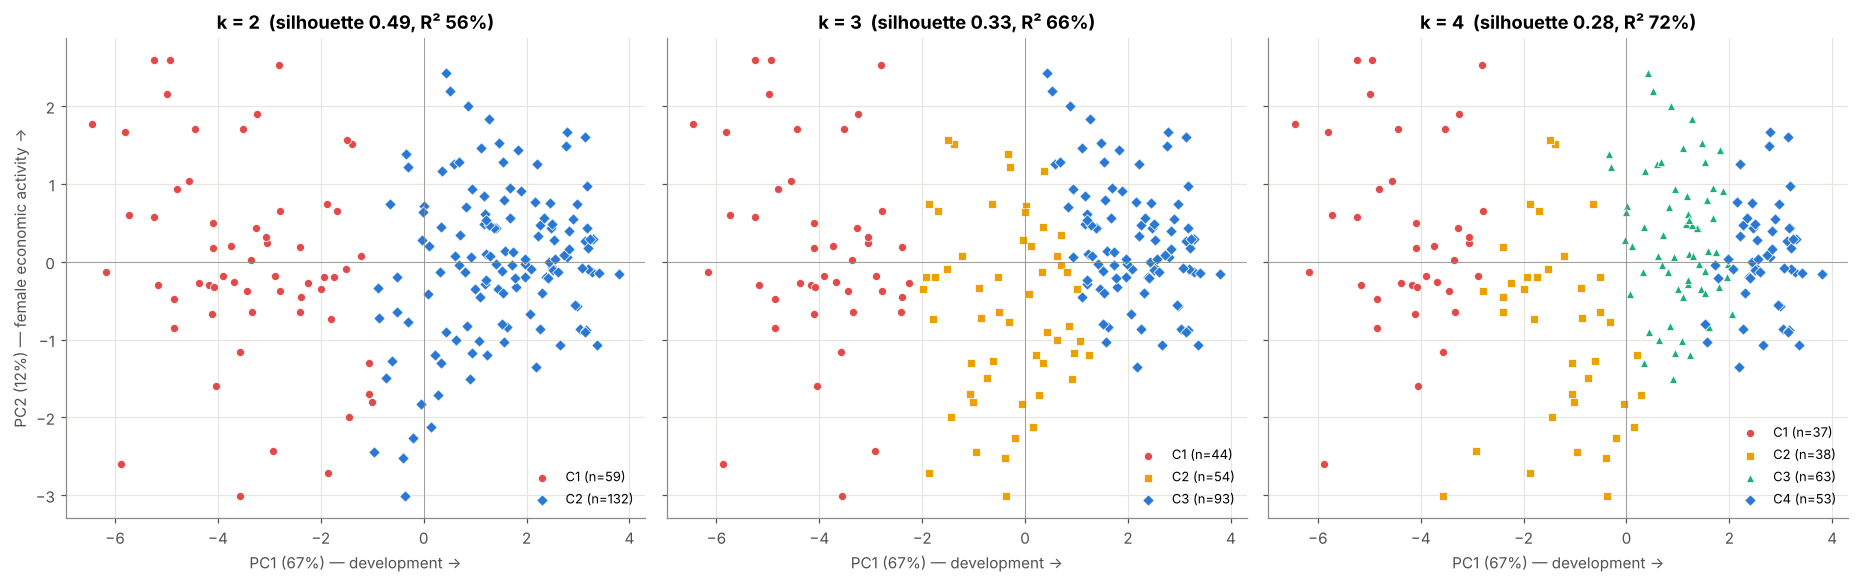

In [28]:
df["k3"] = FITS[3]; df["k4"] = FITS[4]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), sharex=True, sharey=True)
for ax, k in zip(axes, (2, 3, 4)):
    lab = df[f"k{k}"].values
    cols = [RED, BLUE] if k == 2 else ([RED, "#eda100", BLUE] if k == 3 else LEVEL_COLORS)
    mks = ["o", "D"] if k == 2 else (["o", "s", "D"] if k == 3 else LEVEL_MARKERS)
    for c in range(1, k + 1):
        m = lab == c
        ax.scatter(df.PC1[m], df.PC2[m], s=28, color=cols[c-1], marker=mks[c-1], edgecolor="white", lw=0.5,
                   label=f"C{c} (n={m.sum()})")
    ax.set_title(f"k = {k}  (silhouette {metrics.silhouette[k]:.2f}, R² {metrics.R2[k]:.0%})")
    ax.axhline(0, color=MUTED, lw=0.5); ax.axvline(0, color=MUTED, lw=0.5)
    ax.set_xlabel(f"PC1 ({evr[0]:.0%}) — development →"); ax.legend(loc="lower right", fontsize=8.5)
axes[0].set_ylabel(f"PC2 ({evr[1]:.0%}) — female economic activity →")
plt.tight_layout(); plt.savefig(FIG / "09_pca_k2_k3_k4.png"); plt.show()

k=2: countries with silhouette < 0.1 (borderline): 3%;  negative: 0%
k=4: countries with silhouette < 0.1 (borderline): 13%;  negative: 2%


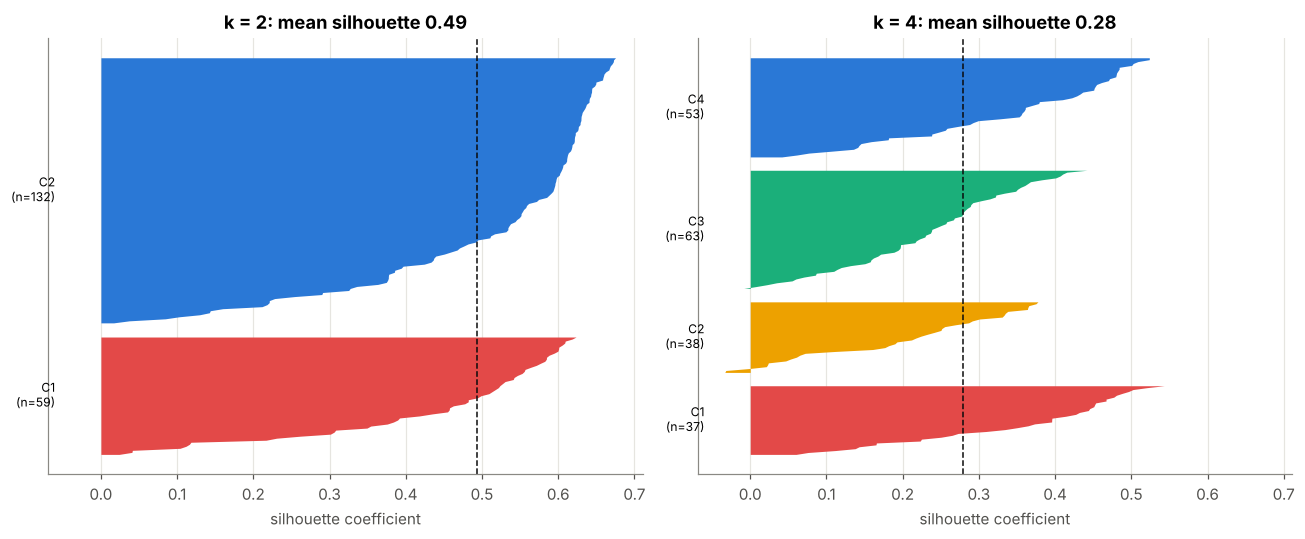

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, k in [(axes[0], 2), (axes[1], 4)]:
    lab = df[f"k{k}"].values
    sil = silhouette_samples(Z, lab); y0 = 0
    cols = [RED, BLUE] if k == 2 else LEVEL_COLORS
    for c in range(1, k + 1):
        s = np.sort(sil[lab == c]); nn = len(s)
        ax.fill_betweenx(np.arange(y0, y0 + nn), 0, s, color=cols[c - 1], lw=0)
        ax.text(-0.06, y0 + nn / 2, f"C{c}\n(n={nn})", fontsize=8, ha="right", va="center")
        y0 += nn + 6
    ax.axvline(sil.mean(), color=INK, ls="--", lw=1)
    ax.set_title(f"k = {k}: mean silhouette {sil.mean():.2f}")
    ax.set_yticks([]); ax.set_xlabel("silhouette coefficient"); ax.grid(axis="y", visible=False)
    print(f"k={k}: countries with silhouette < 0.1 (borderline): {(sil < 0.1).mean():.0%};  negative: {(sil < 0).mean():.0%}")
plt.tight_layout(); plt.savefig(FIG / "10_silhouette_profiles.png"); plt.show()

The PCA maps show what the metrics mean: every solution mostly cuts the cloud into **vertical slices along PC1**, and **there is no empty gap between the groups** — a sign of a continuum with soft boundaries, not of separate islands. At k = 4, PC2 (women's labour-force participation) separates C2 (low female activity, bottom of the map) from the rest of the middle.

The silhouette profiles confirm it: at k = 2 almost every country fits its cluster well (3% borderline). At k = 4, 13% of countries are borderline (silhouette < 0.1) and 2% fit a neighbouring cluster slightly better — the cost of drawing lines through a continuum. These borderline countries are discussed in Part 4.

### 3.4 Cross-check with hierarchical clustering (Ward, as in Session 7)

Largest merge heights (top of the tree): [43.8 17.9 14.  11.4  9.8  9.7]


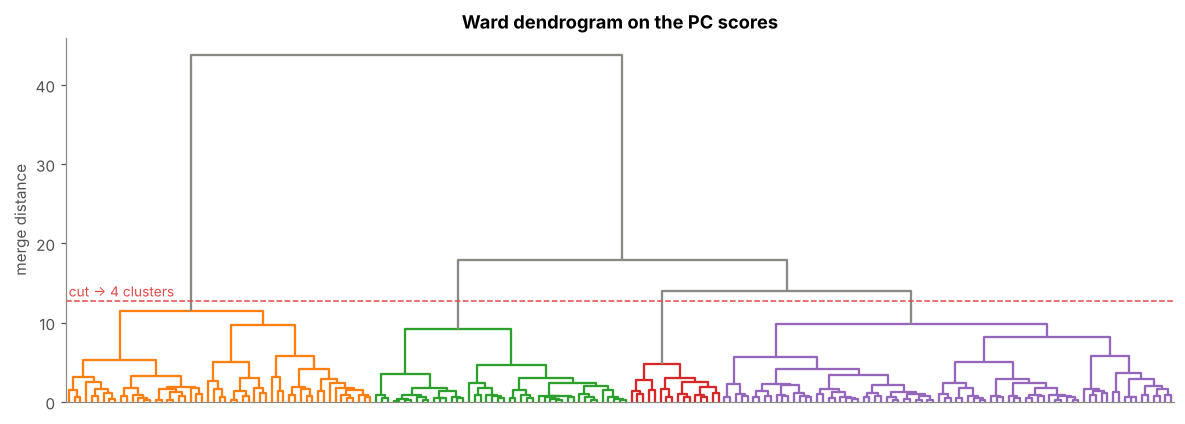

Agreement with K-Means: k=2 ARI = 0.83  |  k=4 ARI = 0.67


In [30]:
link = linkage(Z, method="ward", metric="euclidean")
heights = link[::-1, 2][:6]
print("Largest merge heights (top of the tree):", np.round(heights, 1))
fig, ax = plt.subplots(figsize=(13, 4.3))
cut4 = (link[-4, 2] + link[-3, 2]) / 2
dendrogram(link, no_labels=True, color_threshold=cut4, above_threshold_color=MUTED, ax=ax)
ax.axhline(cut4, color=RED, ls="--", lw=1); ax.text(5, cut4 + 0.6, "cut → 4 clusters", color=RED, fontsize=9)
ax.set_title("Ward dendrogram on the PC scores"); ax.set_ylabel("merge distance"); ax.grid(False)
plt.savefig(FIG / "11_ward_dendrogram.png"); plt.show()
ward2 = fcluster(link, 2, criterion="maxclust"); ward4 = fcluster(link, 4, criterion="maxclust")
print(f"Agreement with K-Means: k=2 ARI = {adjusted_rand_score(df.k2, ward2):.2f}  |  k=4 ARI = {adjusted_rand_score(df.k4, ward4):.2f}")

**What the dendrogram says.** The tallest merge (43.8) dwarfs all others, so Ward also makes its first cut at k = 2 — almost the same split as K-Means (ARI 0.83). Below that, merges happen at similar heights (17.9, 14.0, 11.4): there is **no second natural cut**, which is the signature of a continuum. Ward's 4 groups are still ordered along the development axis but draw the internal boundaries somewhat differently (ARI 0.67 with K-Means). Both methods agree on the substance — an ordered gradient with several levels — while the exact lines depend on the method.

### 3.5 Our preferred k, and how it compares with k = 2

In [31]:
comp = pd.DataFrame({
    "k = 2": [metrics.silhouette[2], metrics.davies_bouldin[2], metrics.R2[2] * 100, metrics.stability[2], metrics.smallest[2]],
    "k = 4": [metrics.silhouette[4], metrics.davies_bouldin[4], metrics.R2[4] * 100, metrics.stability[4], metrics.smallest[4]],
}, index=["silhouette", "Davies-Bouldin", "R² (% structure captured)", "bootstrap stability (ARI)", "smallest cluster"]).round(2)
print(comp.to_string())
print("\nHow the 2-cluster world is re-cut by the 4-cluster solution (number of countries):")
pd.crosstab(df.k2.map({1: "k=2: C1 'developing'", 2: "k=2: C2 'developed'"}), df.k4.map(lambda c: f"k=4: C{c}"))

                           k = 2  k = 4
silhouette                  0.49   0.28
Davies-Bouldin              0.78   1.21
R² (% structure captured)  55.92  71.91
bootstrap stability (ARI)   0.94   0.76
smallest cluster           59.00  37.00

How the 2-cluster world is re-cut by the 4-cluster solution (number of countries):


k4,k=4: C1,k=4: C2,k=4: C3,k=4: C4
k2,,,,
k=2: C1 'developing',37,22,0,0
k=2: C2 'developed',0,16,63,53


**Our choice: k = 4.**

* **Why not 2:** the two-cluster solution is the best *separated* (silhouette 0.49 vs 0.28), but it captures only **56% of the structure versus 72%** for k = 4, and it lumps Switzerland with Tajikistan. The crosstab shows the problem: all 63 countries of the middle group (C3) and 16 of the 38 early-transition countries (C2) are put in the same "developed" cluster as the 53 high-income countries, while the other 22 C2 countries are put with the poorest.
* **Why not 3:** k = 3 is a reasonable runner-up (silhouette 0.33, stability 0.78). Moving to 4 still removes 16% of the remaining within-cluster variation, adds 6 points of R², keeps stability almost unchanged (0.76), and splits the middle into two groups that are clearly different (Part 4).
* **Why not 5 or more:** every extra cluster adds less and is less reproducible (stability 0.71 at k = 5, 0.62 at k = 6).

**Honest caveat:** on a continuum every cut is partly a judgement. k = 4 is chosen on the *combined* evidence — elbow region, structure captured, stability and interpretability — not on a single decisive index. k = 3 and k = 5 are also defensible.

### 3.6 Is the 4-cluster result robust to our choices?
We re-run k = 4 under reasonable alternative choices — including each teammate's original choices — and compare with the main solution using ARI (1 = identical).

In [32]:
def km4_labels(Xalt):
    Pa = PCA().fit_transform(StandardScaler().fit_transform(Xalt))[:, :N90]
    return KMeans(4, n_init=100, random_state=SEED).fit_predict(Pa)

rows = []
add = lambda name, lab, idx=None: rows.append({"alternative": name,
        "ARI vs main solution": round(adjusted_rand_score(df.k4 if idx is None else df.k4[idx], lab), 2)})

add("K-Means on all 10 scaled variables (no PCA)", KMeans(4, n_init=100, random_state=SEED).fit_predict(X))
add("Region-median imputation instead of regression", km4_labels(X_reg))
add("Global-median imputation (Session 7 approach)", km4_labels(X_glob))
X_log4 = df[FEATURES].copy()
for c in ["infantMortality", "illiteracyMale", "illiteracyFemale"]:
    X_log4[c] = np.log1p(X_log4[c])
X_log4 = pd.DataFrame(IterativeImputer(max_iter=50, random_state=0).fit_transform(X_log4), columns=FEATURES)
add("Also log infant mortality and illiteracy", km4_labels(X_log4))
keep = ~is_outlier
add("Without the multivariate outliers", km4_labels(X_imp[keep]), idx=keep)
add("Hierarchical clustering (Ward) on the same PCs", ward4)
# Each teammate's original set-up, compared on the countries both analyses contain
FR = FEATURES_RAW
# Draft A: all 207 countries, raw GDP (no log), global-median imputation, 5 PCs
XA = raw[FR].fillna(raw[FR].median())
labA = KMeans(4, n_init=100, random_state=SEED).fit_predict(PCA(5).fit_transform(StandardScaler().fit_transform(XA)))
inA = raw.country.isin(df.country).values
add("Draft A set-up (207 countries, raw GDP, global median, 5 PCs)", labA[inA])
# Draft B: countries with <= 5 missing, log1p of 4 skewed variables, regression imputation, 4 PCs
selB = raw[FR].isna().sum(axis=1) <= 5
XB = raw.loc[selB, FR].copy()
for c in ["infantMortality", "GDPperCapita", "illiteracyMale", "illiteracyFemale"]:
    XB[c] = np.log1p(XB[c])
XB = IterativeImputer(max_iter=50, random_state=0).fit_transform(XB)
labB = KMeans(4, n_init=300, random_state=SEED).fit_predict(PCA(4).fit_transform(StandardScaler().fit_transform(XB)))
inB = raw.loc[selB, "country"].isin(df.country).values
add("Draft B set-up (198 countries, log of 4 variables, regression imputation)", labB[inB])
seed_aris = [adjusted_rand_score(df.k4, KMeans(4, n_init=10, random_state=s).fit_predict(Z)) for s in range(10)]
rows.append({"alternative": "K-Means with only 10 starts, worst of 10 seeds", "ARI vs main solution": round(min(seed_aris), 2)})
robust = pd.DataFrame(rows).set_index("alternative")
robust

,ARI vs main solution
alternative,
K-Means on all 10 scaled variables (no PCA),0.90
Region-median imputation instead of regression,0.80
Global-median imputation (Session 7 approach),0.89
Also log infant mortality and illiteracy,0.46
Without the multivariate outliers,0.98
Hierarchical clustering (Ward) on the same PCs,0.67
"Draft A set-up (207 countries, raw GDP, global median, 5 PCs)",0.50
"Draft B set-up (198 countries, log of 4 variables, regression imputation)",0.51
"K-Means with only 10 starts, worst of 10 seeds",0.98


In [33]:
lab_log4 = km4_labels(X_log4)
med = pd.concat([df[FEATURES_RAW], pd.Series(lab_log4, name="c")], axis=1).groupby("c")[["illiteracyFemale", "GDPperCapita", "lifeFemale"]].median()
print("If illiteracy is logged, one cluster becomes 'near-zero illiteracy' countries:")
cl = med.illiteracyFemale.idxmin()
print(med.round(1).to_string())
print("\nMembers of that cluster:", ", ".join(df.country[lab_log4 == cl].str.replace(".", " ", regex=False)))

If illiteracy is logged, one cluster becomes 'near-zero illiteracy' countries:
   illiteracyFemale  GDPperCapita  lifeFemale
c                                            
0              22.0        2305.0        71.7
1              58.2         367.0        52.9
2               5.6       16710.5        79.7
3               0.7        1106.0        73.5

Members of that cluster: American Samoa, Armenia, Azerbaijan, Belarus, Bulgaria, Cook Islands, Estonia, Georgia, Guyana, Hungary, Kazakhstan, Korea Dem Peoples Rep, Kyrgyzstan, Latvia, Lithuania, Macedonia, Moldova, Palau, Peru, Poland, Romania, Russia, Saint Kitts, Samoa, Solomon Islands, Suriname, Tajikistan, Tonga, Trinidad and Tobago, Turkmenistan, Ukraine, Uzbekistan, Viet Nam, Yugoslavia


**What survives and what doesn't**
* **Robust:** clustering without PCA (ARI 0.90), region-median or global-median imputation (0.80 and 0.89), removing the outlier (0.98) and fewer K-Means starts (0.98) all give almost the same four groups. Our main preparation choices do not drive the result.
* **Sensitive:** the **transformation of illiteracy** (ARI 0.46). Logging it creates a "near-zero illiteracy" cluster of former Soviet and Eastern European countries (Russia, Ukraine, Poland, Kazakhstan, Viet Nam…) with *lower* median GDP (\$1,106) than the cluster below it (\$2,305). That grouping reflects reported illiteracy of 0.2–0.5% rather than overall development, which is why we keep illiteracy unlogged.
* **Our three drafts:** each teammate's original set-up agrees only moderately with the final solution (ARI ≈ 0.50). Draft A kept countries with almost no data and used raw GDP (so GDP dominated a component); Draft B logged illiteracy. Both drafts nevertheless reached the **same conclusions**: k = 2 has the best silhouette but is not meaningful, k = 4 is preferred, the lowest-development and high-income groups are stable, and the **boundaries in the middle are soft**.

---
## Part 4 — Put Countries Back into the Analysis

### 4.1 Who is in each cluster?
Medians in original units (medians because GDP is so skewed), computed on **observed values only**, so imputed numbers do not shape the profiles.

In [34]:
LEVEL_NAMES = {1: "Level 1 · Low income, high mortality",
               2: "Level 2 · Early transition",
               3: "Level 3 · The middle",
               4: "Level 4 · High income, long lives"}
show = ["tfr", "contraception", "lifeMale", "lifeFemale", "infantMortality", "GDPperCapita",
        "economicActivityMale", "economicActivityFemale", "illiteracyMale", "illiteracyFemale"]
prof = df.groupby("k4")[show].median().round(1)
prof.insert(0, "n", df.k4.value_counts().sort_index())
prof["GDP $/day"] = (prof.GDPperCapita / 365).round(1)
prof.index = [f"C{c} · {LEVEL_NAMES[c]}" for c in prof.index]
prof.T

,"C1 · Level 1 · Low income, high mortality",C2 · Level 2 · Early transition,C3 · Level 3 · The middle,"C4 · Level 4 · High income, long lives"
n,37.0,38.0,63.0,53.0
tfr,5.8,4.8,2.8,1.7
contraception,12.0,33.0,53.0,71.0
lifeMale,48.7,62.1,67.5,73.5
lifeFemale,51.6,63.3,74.0,79.6
infantMortality,103.0,56.0,23.0,7.0
GDPperCapita,293.0,1155.5,1860.0,14111.0
economicActivityMale,83.9,77.0,79.0,70.6
economicActivityFemale,49.9,30.0,49.0,50.5
illiteracyMale,43.8,22.0,5.0,2.4


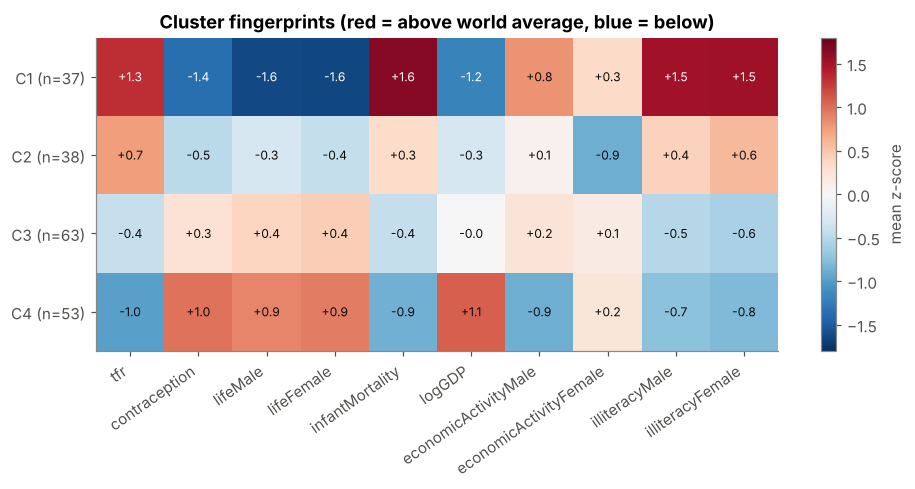

In [35]:
zprof = pd.DataFrame(X, columns=FEATURES).groupby(df.k4).mean()
fig, ax = plt.subplots(figsize=(10, 3.7))
im = ax.imshow(zprof.values, cmap="RdBu_r", vmin=-1.8, vmax=1.8, aspect="auto")
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=35, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels([f"C{c} (n={(df.k4 == c).sum()})" for c in range(1, 5)])
for i in range(4):
    for j in range(len(FEATURES)):
        v = zprof.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1.1 else INK)
ax.grid(False); plt.colorbar(im, ax=ax, label="mean z-score")
ax.set_title("Cluster fingerprints (red = above world average, blue = below)")
plt.savefig(FIG / "12_cluster_fingerprints.png"); plt.show()

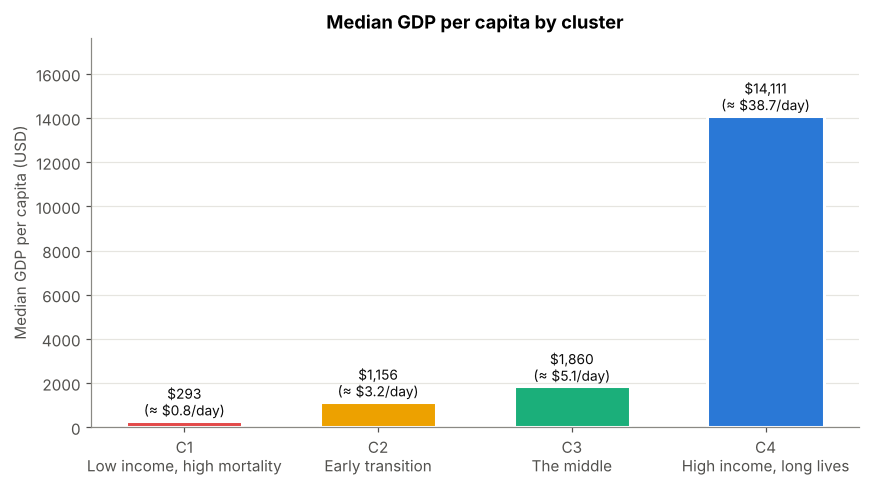

In [36]:
med_gdp = df.groupby("k4").GDPperCapita.median()
fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.bar([f"C{c}\n{LEVEL_NAMES[c].split(' · ')[1]}" for c in med_gdp.index], med_gdp.values,
              color=LEVEL_COLORS, width=0.6, edgecolor="white", linewidth=2)
for b, v in zip(bars, med_gdp.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 250, f"${v:,.0f}\n(≈ ${v/365:.1f}/day)", ha="center", fontsize=9, color=INK)
ax.set_ylabel("Median GDP per capita (USD)"); ax.set_ylim(0, med_gdp.max() * 1.25)
ax.set_title("Median GDP per capita by cluster"); ax.grid(axis="x", visible=False)
plt.savefig(FIG / "13_median_gdp_by_cluster.png"); plt.show()

In [37]:
print("Region composition (number of countries):")
pd.crosstab(df.k4.map(lambda c: f"C{c}"), df.region, margins=True)

Region composition (number of countries):


region,Africa,America,Asia,Europe,Oceania,All
k4,,,,,,
C1,30,1,6,0,0,37
C2,18,4,12,0,4,38
C3,3,19,23,9,9,63
C4,1,13,7,29,3,53
All,52,37,48,38,16,191


In [38]:
members = (df.sort_values("PC1").groupby("k4").country
             .apply(lambda s: ", ".join(s.str.replace(".", " ", regex=False))).to_frame("countries (ordered from least to most developed)"))
members.insert(0, "n", df.k4.value_counts().sort_index())
members.index = [f"C{c} · {LEVEL_NAMES[c]}" for c in members.index]
members

,n,countries (ordered from least to most developed)
"C1 · Level 1 · Low income, high mortality",37,"Sierra Leone, Niger, Afghanistan, Burkina Faso, Mali, Ethiopia, Burundi, Guinea, Malawi, Mozambique, Liberia, Chad, Guinea Bissau, Uganda, Rwanda, Gambia, Bhutan, Mauritania, Eritrea, Benin, Ivory Coast, Senegal, Djibouti, Togo, Nepal, Sudan, Central African Rep, Laos, Haiti, Nigeria, Equatorial Guinea, Zambia, Tanzania, Dem Rep of the Congo, Comoros, Cambodia, Bangladesh"
C2 · Level 2 · Early transition,38,"Yemen, Pakistan, Madagascar, Cameroon, Congo, Ghana, Gabon, Sao Tome, Lesotho, Kenya, Iraq, India, Botswana, Zimbabwe, Papua New Guinea, Vanuatu, Guatemala, Kiribati, Namibia, Morocco, Swaziland, Egypt, Oman, Myanmar, Nicaragua, Maldives, Bolivia, Libya, Cape Verde, Honduras, Algeria, Saudi Arabia, Marshall Islands, Iran, Syria, Jordan, Micronesia, Tunisia"
C3 · Level 3 · The middle,63,"Turkmenistan, Tajikistan, South Africa, Mongolia, Indonesia, El Salvador, Guyana, Samoa, Qatar, Philippines, Kyrgyzstan, Solomon Islands, Paraguay, Viet Nam, Moldova, Azerbaijan, Belize, Uzbekistan, Dominican Republic, Ecuador, St Vincent, Brazil, Turkey, China, United Arab Emirates, Saint Lucia, Georgia, Fiji, Mexico, Bahrain, Malaysia, Kazakhstan, Armenia, Ukraine, Cook Islands, Korea Dem Peoples Rep, Venezuela, Seychelles, Lebanon, Kuwait, Northern Mariana Islands, Russia, Saint Kitts, Palau, Colombia, New Caledonia, Mauritius, Thailand, Panama, Belarus, Sri Lanka, Jamaica, Tonga, Chile, Latvia, Romania, Yugoslavia, Argentina, Lithuania, Guam, Brunei, Trinidad and Tobago, Costa Rica"
"C4 · Level 4 · High income, long lives",53,"Suriname, Peru, French Guiana, Macedonia, Uruguay, French Polynesia, Estonia, Malta, Bahamas, Poland, Reunion, Bulgaria, American Samoa, Macau, Croatia, Cuba, Guadeloupe, Barbados, Czech Republic, Cyprus, Slovakia, Hungary, Korea Republic of, Netherlands Antilles, Portugal, Puerto Rico, Singapore, Denmark, Iceland, Martinique, New Zealand, Slovenia, United States, Israel, Netherlands, Ireland, Greece, Japan, Australia, Sweden, Spain, Luxembourg, Switzerland, Norway, Canada, Hong Kong, Belgium, United Kingdom, Austria, Finland, Italy, Germany, France"


**The four clusters form an ordered sequence along the development axis**, which is why we name them after the four levels in *Factfulness*:

| Cluster | n | Fertility | Infant mortality | Female life exp. | Female illiteracy | Female econ. activity | Median GDP/cap | ≈ \$/day |
|---|---|---|---|---|---|---|---|---|
| **C1 · Level 1** — low income, high mortality | 37 | 5.8 | 103 | 52 | 70% | 50% | \$293 | 0.8 |
| **C2 · Level 2** — early transition | 38 | 4.8 | 56 | 63 | 40% | **30%** | \$1,156 | 3.2 |
| **C3 · Level 3** — the middle | 63 | 2.8 | 23 | 74 | 8% | 49% | \$1,860 | 5.1 |
| **C4 · Level 4** — high income, long lives | 53 | 1.7 | 7 | 80 | 5% | 51% | \$14,111 | 38.7 |

* **Geography:** C1 is 30 of 37 African; C2 mixes Africa (18), Asia (12) and the Pacific; C3 is the most diverse (Latin America, Asia, former USSR, Gulf); C4 is mostly Europe (29) plus North America, Japan, Australia and Caribbean territories.
* **Fingerprints:** C1 and C4 are extreme on almost every variable. C2 and C3 differ mainly in fertility, infant mortality and literacy, and **C2 is the only cluster with clearly low female economic activity** (the PC2 axis).
* **Link to Factfulness:** Rosling's levels are defined by income per person per day (Level 1 below \$2, Level 2 \$2–8, Level 3 \$8–32, Level 4 above \$32), in today's purchasing-power dollars. Our GDP figures are 1990s market-rate dollars, so the numbers are not directly comparable, but the **ordering and the jumps** match: C1 corresponds to Level 1 (life without shoes, water fetched on foot), C2 to Level 2 (shoes, a bicycle, but still high child mortality), C3 to Level 3 (a motorbike, running water, children in secondary school) and C4 to Level 4. The biggest single income jump is between C3 and C4, while the biggest jumps in **health and fertility** are between C1, C2 and C3 — the middle of the world has largely caught up on how long people live, much less on income.

### 4.2 Choosing one representative country per cluster
A representative should be **typical** and **well measured**. We rank countries by distance to their cluster centroid (in the PC space), keep only countries with **at most 1 imputed value** (so we are not describing estimated numbers), and choose a well-known country among the closest ones.

In [39]:
centroids = pd.DataFrame(Z).groupby(df.k4).mean()
df["dist_to_centroid"] = [np.linalg.norm(Z[i] - centroids.loc[c].values) for i, c in enumerate(df.k4)]
df["n_imputed"] = feat_mask.sum(axis=1).values
df["silhouette_k4"] = silhouette_samples(Z, df.k4)
df["rank_in_cluster"] = df.groupby("k4").dist_to_centroid.rank().astype(int)
for c in range(1, 5):
    sub = df[(df.k4 == c) & (df.n_imputed <= 1)].nsmallest(8, "dist_to_centroid")
    print(f"C{c} (n={(df.k4 == c).sum()}): " + ", ".join(f"{r.country} (#{r.rank_in_cluster})" for r in sub.itertuples()))

C1 (n=37): Togo (#3), Ethiopia (#5), Haiti (#6), Ivory.Coast (#12), Guinea (#13), Nepal (#14), Benin (#15), Nigeria (#17)
C2 (n=38): India (#2), Myanmar (#5), Botswana (#8), Nicaragua (#9), Egypt (#11), Marshall.Islands (#13), Cape.Verde (#15), Guatemala (#16)
C3 (n=63): Ecuador (#2), Colombia (#4), Tonga (#8), New.Caledonia (#9), Venezuela (#10), Malaysia (#11), Dominican.Republic (#12), Panama (#14)
C4 (n=53): Netherlands.Antilles (#1), Guadeloupe (#3), Portugal (#4), Martinique (#5), Korea.Republic.of (#7), Cuba (#14), Barbados (#17), United.States (#20)


In [40]:
REPS = {1: "Ethiopia", 2: "India", 3: "Colombia", 4: "Portugal"}
REP_OFFSETS = {1: (12, 14), 2: (10, 14), 3: (-100, -40), 4: (8, -38)}
OTHER_LABELS = ["Saudi.Arabia", "Cuba", "Qatar", "China", "Peru", "Norway", "Haiti", "Nigeria"]
rep = df.set_index("country").loc[list(REPS.values())]
rep_tbl = rep[["region", "k4", "rank_in_cluster", "n_imputed", "silhouette_k4"] + show].copy()
rep_tbl.index = [f"C{c} · {n}" for c, n in REPS.items()]
print("Representative countries (raw values; NaN = not reported):")
rep_tbl.T.round(2)

Representative countries (raw values; NaN = not reported):


,C1 · Ethiopia,C2 · India,C3 · Colombia,C4 · Portugal
region,Africa,Asia,America,Europe
k4,1,2,3,4
rank_in_cluster,5,2,4,4
n_imputed,0,0,0,0
silhouette_k4,0.543188,0.377494,0.267921,0.482279
tfr,7.0,3.07,2.69,1.48
contraception,4.0,41.0,72.0,66.0
lifeMale,48.4,62.1,68.2,71.8
lifeFemale,51.6,62.7,73.7,78.9
infantMortality,107.0,72.0,24.0,8.0


In [41]:
rows = []
for c, name in REPS.items():
    medc = df.loc[df.k4 == c, show].median()
    rows.append(((df.set_index("country").loc[name, show] / medc - 1) * 100).rename(name))
print("Representative's value relative to its own cluster median (% above/below):")
pd.DataFrame(rows).round(0)

Representative's value relative to its own cluster median (% above/below):


,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
Ethiopia,20.0,-67.0,-1.0,0.0,4.0,-67.0,1.0,17.0,24.0,7.0
India,-36.0,24.0,0.0,-1.0,29.0,-68.0,4.0,12.0,57.0,55.0
Colombia,-2.0,36.0,1.0,-0.0,4.0,19.0,0.0,2.0,76.0,2.0
Portugal,-14.0,-7.0,-2.0,-1.0,14.0,-26.0,-5.0,-3.0,207.0,177.0


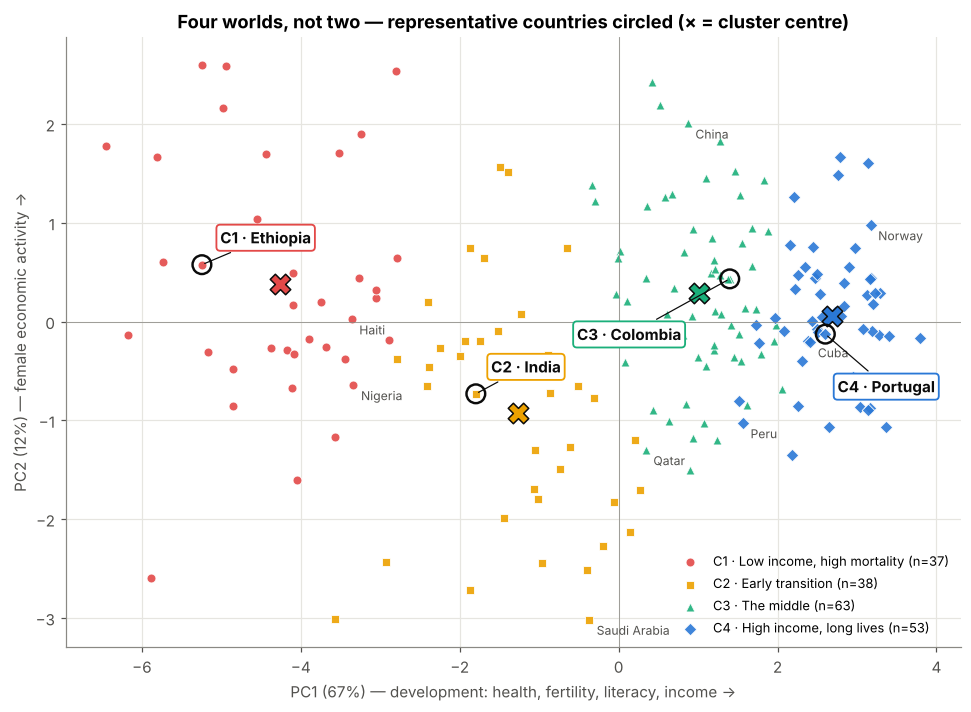

In [42]:
fig, ax = plt.subplots(figsize=(10.5, 7.2))
for c in range(1, 5):
    s = df[df.k4 == c]
    ax.scatter(s.PC1, s.PC2, s=34, color=LEVEL_COLORS[c - 1], marker=LEVEL_MARKERS[c - 1],
               edgecolor="white", lw=0.6, alpha=0.9, label=f"C{c} · {LEVEL_NAMES[c].split(' · ')[1]} (n={len(s)})")
    ax.scatter(s.PC1.mean(), s.PC2.mean(), s=180, marker="X", color=LEVEL_COLORS[c - 1], edgecolor=INK, lw=1, zorder=4)
    r = df[df.country == REPS[c]].iloc[0]
    ax.scatter(r.PC1, r.PC2, s=150, facecolor="none", edgecolor=INK, lw=1.6, zorder=5)
    ax.annotate(f"C{c} · {REPS[c].replace('.', ' ')}", (r.PC1, r.PC2), REP_OFFSETS[c], textcoords="offset points",
                fontsize=10, fontweight="bold", color=INK, arrowprops=dict(arrowstyle="-", color=INK, lw=0.8),
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=LEVEL_COLORS[c - 1], lw=1.2), zorder=6)
for name in OTHER_LABELS:
    r = df[df.country == name].iloc[0]
    ax.annotate(name.replace(".", " "), (r.PC1, r.PC2), (5, -10), textcoords="offset points", fontsize=8, color=INK2)
ax.axhline(0, color=MUTED, lw=0.5); ax.axvline(0, color=MUTED, lw=0.5)
ax.set_xlabel(f"PC1 ({evr[0]:.0%}) — development: health, fertility, literacy, income →")
ax.set_ylabel(f"PC2 ({evr[1]:.0%}) — female economic activity →")
ax.set_title("Four worlds, not two — representative countries circled (× = cluster centre)")
ax.legend(loc="lower right", fontsize=8.5)
plt.savefig(FIG / "14_four_worlds_representatives.png"); plt.show()

### 4.3 Who is surprising?
Countries far from their cluster centre, countries the algorithm barely assigned (low silhouette), and the poorest vs. richest members of each cluster.

In [43]:
for c in range(1, 5):
    sub = df[df.k4 == c]
    far = sub.nlargest(4, "dist_to_centroid")
    border = sub.nsmallest(4, "silhouette_k4")
    print(f"C{c} · {LEVEL_NAMES[c]}")
    print("   farthest from centre :", ", ".join(f"{r.country} ({r.dist_to_centroid:.1f})" for r in far.itertuples()))
    print("   most borderline      :", ", ".join(f"{r.country} ({r.silhouette_k4:.2f})" for r in border.itertuples()))
    g = sub.dropna(subset=["GDPperCapita"]).sort_values("GDPperCapita")
    print("   poorest / richest    :", ", ".join(f"{r.country} ${r.GDPperCapita:,.0f}" for r in pd.concat([g.head(2), g.tail(2)]).itertuples()))

C1 · Level 1 · Low income, high mortality
   farthest from centre : Afghanistan (3.4), Sierra.Leone (3.0), Cambodia (2.7), Burundi (2.7)
   most borderline      : Comoros (0.06), Dem.Rep.of.the.Congo (0.08), Sudan (0.11), Tanzania (0.14)
   poorest / richest    : Sudan $36, Mozambique $77, Liberia $1,124, Afghanistan $2,848
C2 · Level 2 · Early transition
   farthest from centre : Yemen (3.1), Vanuatu (3.1), Kiribati (2.5), Saudi.Arabia (2.5)
   most borderline      : Bolivia (-0.03), Cape.Verde (-0.03), Vanuatu (-0.00), Honduras (0.02)
   poorest / richest    : Sao.Tome $49, Madagascar $215, Saudi.Arabia $6,583, Iraq $11,308
C3 · Level 3 · The middle
   farthest from centre : United.Arab.Emirates (3.0), Qatar (2.8), Solomon.Islands (2.5), Tajikistan (2.4)
   most borderline      : Brunei (-0.01), Trinidad.and.Tobago (0.01), Latvia (0.02), Jamaica (0.03)
   poorest / richest    : Tajikistan $122, Viet.Nam $270, United.Arab.Emirates $17,690, New.Caledonia $19,450
C4 · Level 4 · High inc

### 4.4 Interpreting the clusters through one country each

> Country values are the raw UN figures from the late 1990s (none of the four representatives has any imputed value). Each one is among the 5 countries closest to its cluster centre.

#### C1 · Level 1 — **Ethiopia**: high fertility, high mortality, extreme poverty
* **Why it belongs here:** 7.0 children per woman, only 4% contraceptive use, infant mortality of 107 per 1,000, life expectancy of 48/52 years, three in four women illiterate and GDP per capita of \$96. It is the 5th closest country to the C1 centre and it has a high silhouette (0.54): it clearly belongs here and nowhere else.
* **Similar to the others?** Yes — fertility, infant mortality and life expectancy are within a few percent of the cluster median. It is poorer than the median and uses less contraception, but in the same direction.
* **What distinguishes this cluster:** the far negative end of PC1 on every health and fertility variable; median income below \$1 a day.
* **Surprising:** C1 is mostly sub-Saharan Africa, but **Haiti, Afghanistan, Nepal, Bangladesh, Laos, Cambodia and Bhutan** are here too. The cluster is defined by living conditions, not by continent. Afghanistan has the highest reported GDP in the cluster (\$2,848) and is the member farthest from the centre — money did not translate into health.

#### C2 · Level 2 — **India**: early transition, with few women in paid work
* **Why it belongs here:** India is the **2nd most typical** C2 country: fertility of 3.1 and falling, 41% contraceptive use and life expectancy of 62/63, but infant mortality still high (72), 62% of women illiterate and only 34% female economic activity.
* **Similar to the others?** On fertility, contraception and life expectancy, yes. On income India looks more like C1 (\$365, 68% below the C2 median), which shows the clusters are driven by health and family size more than by GDP.
* **What distinguishes this cluster:** it sits between C1 and C3 on development and has the **lowest female labour-force participation** of all clusters (median 30%) together with high female illiteracy (40%). Pakistan, Egypt, Morocco, Iran, Syria, Kenya, Ghana and Bolivia are here.
* **Surprising:** **Saudi Arabia, Oman and Libya** sit here despite much higher incomes (Saudi Arabia: \$6,583) — their fertility, female illiteracy and very low female participation (Saudi Arabia: 7%) look like India's, not Europe's. **Botswana, Namibia, Zimbabwe and Lesotho** are here because the AIDS epidemic pulled life expectancy down despite middling incomes.

#### C3 · Level 3 — **Colombia**: the big middle
* **Why it belongs here:** fertility 2.7, contraception 72%, infant mortality 24, life expectancy 68/74, female illiteracy 9% and GDP of \$2,215 — **within a few percent of the C3 median on most variables** (4th closest to the centre); only contraception (72%) and male illiteracy are noticeably higher.
* **Similar to the others?** Yes in profile, though C3 is the largest and most geographically diverse group: Latin America (Brazil, Mexico, Chile, Argentina), Asia (China, Indonesia, Thailand, Philippines, Viet Nam), the former USSR (Russia, Ukraine, Kazakhstan) and the Gulf.
* **What distinguishes this cluster:** fertility near replacement level and good literacy — close to the rich world — but infant mortality still about 3× higher than C4 and only about 1/8 of its income.
* **Surprising:** it contains both **Tajikistan (\$122)** and **New Caledonia (\$19,450)**; the **United Arab Emirates and Qatar** are the members farthest from the centre — incomes like Europe's, health and demography like Colombia's. **Russia** is here, not with Europe, because of very high adult mortality in the 1990s, while **Costa Rica, Argentina and Chile** are among the most developed C3 members, right next to the C4 border.

#### C4 · Level 4 — **Portugal**: low fertility, long lives, high income
* **Why it belongs here:** fertility 1.5, infant mortality 8, life expectancy 72/79 and GDP of \$10,428 — 4th closest to the C4 centre.
* **Similar to the others?** Yes on health, fertility and income. One exception: illiteracy (7.5% male, 13% female) is about three times the cluster median — a legacy of the older generations' schooling, not of today's children.
* **What distinguishes this cluster:** the far positive end of PC1 on every variable: lowest fertility and mortality, highest contraception and life expectancy.
* **Surprising:** **Cuba** (about \$2,000 GDP per capita) and **Suriname, Bulgaria and Uruguay** (all under \$6,000) share the cluster with Switzerland (\$42,416), because their health and fertility indicators match the rich world. **Peru** is the member farthest from the centre (a boundary case), and the Nordic countries are also far out because of their very high female participation. C4 describes *how people live*, not only GDP.

**Overall:** the four clusters are four steps on one development ladder, with PC2 (women's work) adding a second, cultural dimension that sets C2 apart.

---
## Answers to the six research questions

### 1. Can the world be meaningfully divided into only two clusters (developed vs. developing)?
**Statistically yes, meaningfully no.** A two-cluster solution exists and is the best separated (silhouette 0.49), but it is not the "developed vs. developing" divide people imagine. It separates **59 high-fertility, high-mortality countries** from **132 others** and puts Switzerland, Tajikistan and Bolivia in the same "developed" group (GDP from \$122 to \$42,416). It captures only **56% of the data's structure**. It separates a tail, not two worlds.

### 2. How many clusters are suggested by the data according to the Elbow Rule and other metrics?
* **Elbow rule:** a gradual bend in the **k = 4–5** region (the detector picks 5, with 4 virtually tied).
* **Silhouette, Calinski-Harabasz and Davies-Bouldin:** all favour **k = 2**, because they reward the single widest gap in what is otherwise a continuum.
* **R²:** gains shrink after k = 4 (56% → 66% → 72% → 76%).
* **Bootstrap stability:** acceptable up to k = 4 (0.76), then falling (0.71, 0.62).

Weighing all the evidence, we choose **k = 4**, with k = 3 and 5 also defensible.

### 3. How much of the data structure is captured by two clusters compared with our preferred number?
**k = 2 captures 56%** of the total variance (between-cluster sum of squares / total, in the 4-PC space); **k = 4 captures 72%** — 16 percentage points more. Even so, 28% stays *within* clusters, further evidence of a continuum.

### 4. Does the evidence support the *Factfulness* argument that the world is four or more groups, not two?
**Largely yes.** The PCA map and the PC1 histogram show a continuum with most countries in the middle, not two blobs. The four K-Means clusters are ordered along the development axis, and their profiles line up with Rosling's four levels. Two caveats: (1) because the data are a continuum, the exact boundaries depend on method and preparation choices (Ward and the illiteracy transformation move countries in the middle); (2) silhouette alone would pick two groups. Both caveats support Rosling's deeper point: **there is no gap separating "us" from "them"**, only a gradient that is better described by several levels than by two.

### 5. What does PCA tell us about the variables that differentiate countries?
* **One dimension dominates:** PC1 explains **67%** of the variance. Life expectancy, infant mortality, fertility, contraception, illiteracy and income all load on it with similar weight — development is a *bundle*, and health and demography separate countries more than GDP does (log GDP contributes 9% to PC1 vs 13–14% each for female life expectancy and infant mortality).
* **The second dimension is women's economic activity** (PC2, 12%, 82% of it from one variable). It separates countries at the *same* development level, e.g. Saudi Arabia vs. China.
* **4 PCs keep 92%** of the information, so PCA removes redundancy before clustering without changing the groups (ARI 0.90).

### 6. Using one representative country from each cluster, how would you describe the clusters?
* **C1 · Ethiopia — Level 1:** 7 children per woman, infant mortality 107, life expectancy around 50, three in four women illiterate. Mostly sub-Saharan Africa, but also Haiti, Afghanistan, Nepal and Bangladesh.
* **C2 · India — Level 2:** fertility falling (3.1), but infant mortality still high and few women in paid work or literate. Also Pakistan, Egypt, Iran, and, surprisingly, Saudi Arabia and Oman.
* **C3 · Colombia — Level 3:** the large middle: fertility near replacement, good literacy, moderate mortality, modest income. Also China, Brazil, Mexico, Russia, and the Gulf's richest states.
* **C4 · Portugal — Level 4:** low fertility, long lives, high income. Western and Central Europe, North America, Japan, Australia — and Cuba, whose health indicators match the rich world.